In [ ]:
# Locate the organized checkout and use its preserved execution layout.
from pathlib import Path
import os, runpy, sys
_bases = [Path.cwd(), *Path.cwd().parents]
_part2 = next(candidate for base in _bases for candidate in (base, base / "part2")
              if (candidate / "run.py").is_file() and (candidate / "layout.json").is_file())
_workspace = runpy.run_path(str(_part2 / "run.py"))["prepare_workspace"]()
os.chdir(_workspace)
sys.path.insert(0, str(_workspace))


# All Part Two submissions: direct fixed-benchmark comparison

All 13 recipes on the same 13 splits. This notebook reads verified results; rebuilding models is explicit.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'outcome_train.csv').exists() else Path.cwd() / 'part2'
assert (ROOT / 'outcome_train.csv').exists()
RUN = ROOT / 'experiments/all_submissions/runs/8f68385e25e07615'

In [2]:
display(pd.read_csv(RUN / 'comparison_strict.csv').set_index('model'))

,completed_splits,official,temporal,worst,cv,gap_mean,gap_worst,kaggle,forward_wins_vs_ani,gap_wins_vs_ani,temporal_delta_vs_02,cv_delta_vs_02
model,,,,,,,,,,,,
01_balanced_ensemble,10,0.554134,0.537734,0.586815,0.574210,0.567924,0.649045,NaN,2,2,-0.002590,-0.003838
02_text_heavy,10,0.553592,0.540324,0.588906,0.578048,0.568506,0.642620,0.58993,1,1,0.000000,0.000000
03_phase_specialized,10,0.551255,0.537613,0.586144,0.574253,0.568270,0.648905,0.59562,2,2,-0.002711,-0.003795
04_capped_year,10,0.553970,0.538620,0.588823,0.574856,0.565622,0.644112,NaN,1,2,-0.001704,-0.003192
05_text_later_phases,10,0.558605,0.545290,0.594677,0.584955,0.572981,0.644927,NaN,0,0,0.004966,0.006907
06_lighter_tree_blend,10,0.555718,0.542462,0.591366,0.581058,0.570345,0.643195,NaN,0,0,0.002138,0.003010
07_ani_mild_phase3_trend,10,0.555034,0.537306,0.588557,0.586776,0.563816,0.628806,NaN,2,3,-0.003018,0.008728
08_ani_linear25,10,0.553327,0.538022,0.588732,0.585189,0.565438,0.632229,NaN,1,0,-0.002301,0.007141
09_ani_replace_knn5,10,0.560796,0.535213,0.586014,0.589230,0.563657,0.630312,NaN,3,2,-0.005111,0.011182


In [3]:
display(pd.read_csv(RUN / 'comparison_published.csv').set_index('model'))

,completed_splits,official,temporal,worst,cv,gap_mean,gap_worst,kaggle,forward_wins_vs_ani,gap_wins_vs_ani,temporal_delta_vs_02,cv_delta_vs_02
model,,,,,,,,,,,,
01_balanced_ensemble,10,0.554134,0.537734,0.586815,0.574210,0.567924,0.649045,NaN,2,2,-0.002590,-0.003838
02_text_heavy,10,0.553592,0.540324,0.588906,0.578048,0.568506,0.642620,0.58993,1,1,0.000000,0.000000
03_phase_specialized,10,0.551255,0.537613,0.586144,0.574253,0.568270,0.648905,0.59562,2,2,-0.002711,-0.003795
04_capped_year,10,0.553970,0.538620,0.588823,0.574856,0.565622,0.644112,NaN,1,2,-0.001704,-0.003192
05_text_later_phases,10,0.558605,0.545290,0.594677,0.584955,0.572981,0.644927,NaN,0,0,0.004966,0.006907
06_lighter_tree_blend,10,0.555718,0.542462,0.591366,0.581058,0.570345,0.643195,NaN,0,0,0.002138,0.003010
07_ani_mild_phase3_trend,10,0.556118,0.535617,0.587627,0.584866,0.562949,0.626857,NaN,2,3,-0.004707,0.006818
08_ani_linear25,10,0.553741,0.536658,0.587988,0.583451,0.564789,0.630558,NaN,1,0,-0.003666,0.005403
09_ani_replace_knn5,10,0.561697,0.533687,0.586055,0.587178,0.562923,0.628877,NaN,3,2,-0.006637,0.009130


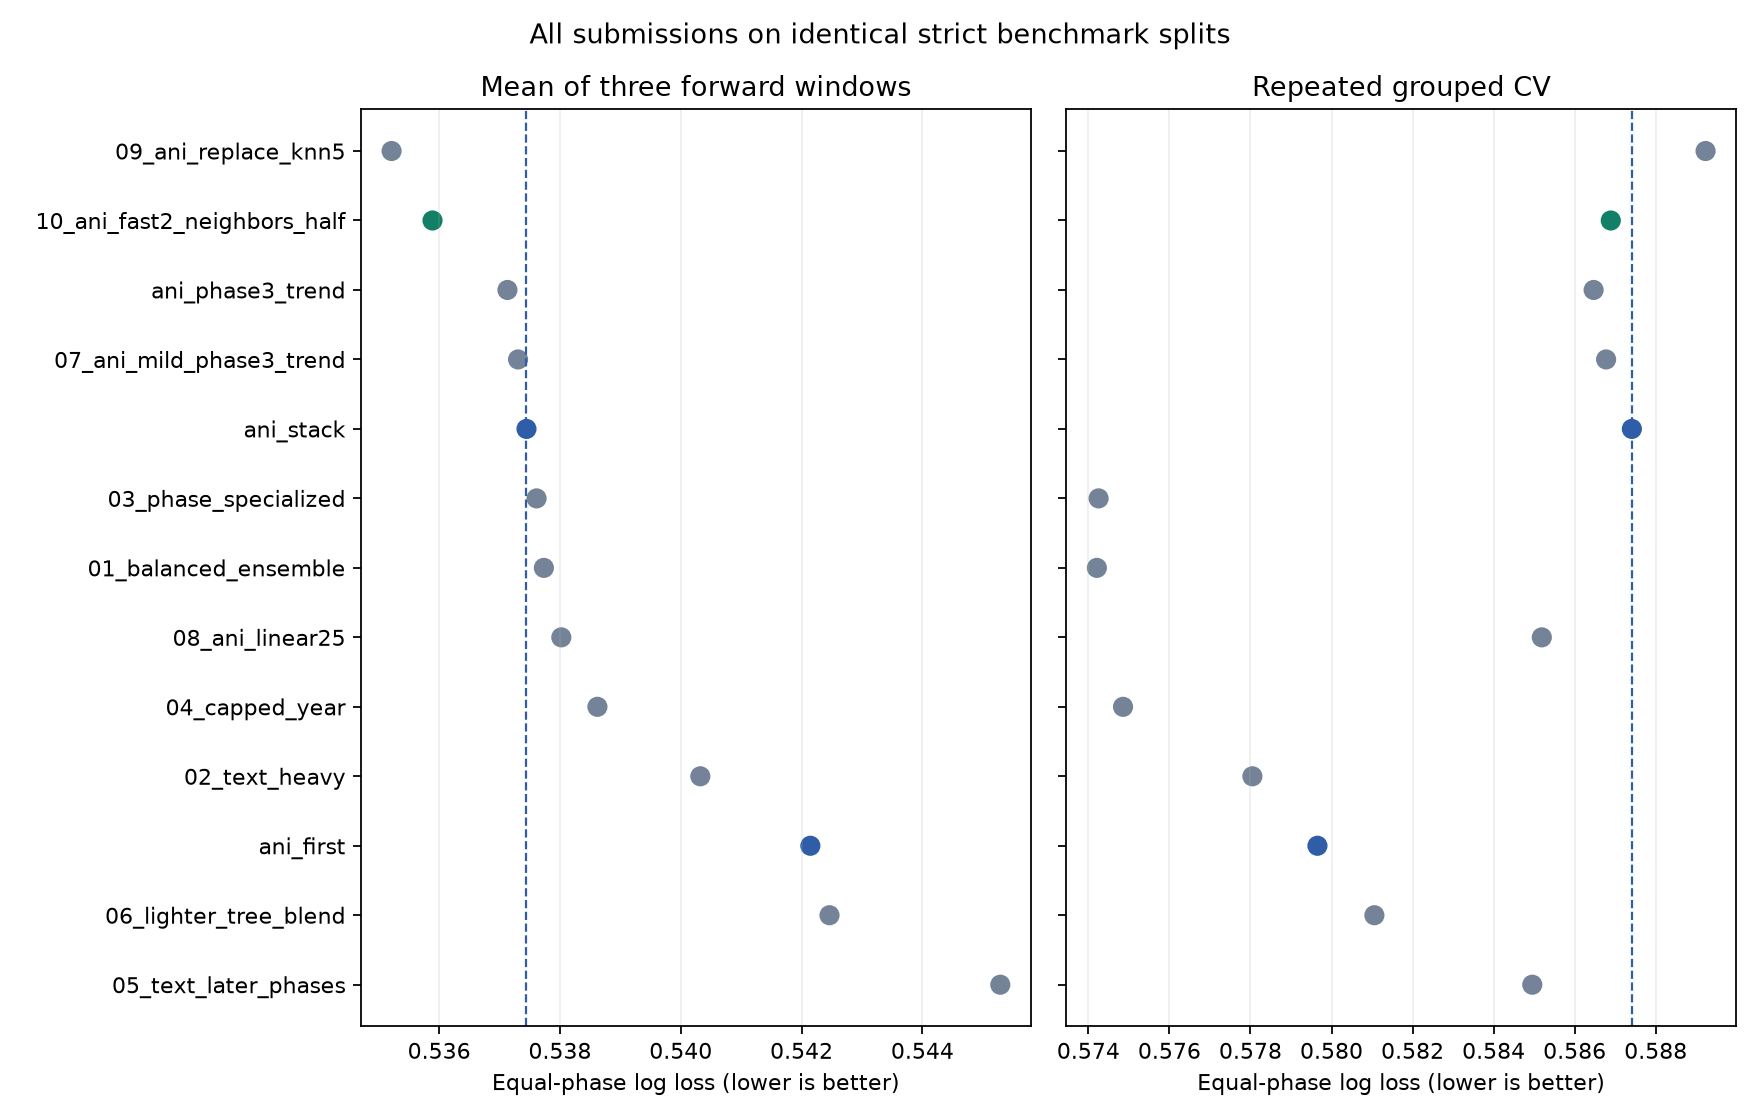

In [4]:
display(Image(filename=str(RUN / 'figures/comparison.png')))

In [5]:
paired = pd.read_csv(RUN / 'paired_comparisons.csv')
display(paired[(paired.track == 'strict') & paired.reference.isin(['02_text_heavy','03_phase_specialized','ani_first','ani_stack'])])

,track,suite,model,reference,kind,delta,lower,upper,trials,bootstrap_repetitions
3,strict,main,10_ani_fast2_neighbors_half,02_text_heavy,temporal,-0.004434,-0.010836,0.002037,3478,2000
4,strict,main,10_ani_fast2_neighbors_half,02_text_heavy,group_cv,0.008844,0.005142,0.012683,8436,2000
5,strict,gaps,10_ani_fast2_neighbors_half,02_text_heavy,temporal,-0.005317,-0.011461,0.000652,3478,2000
6,strict,main,10_ani_fast2_neighbors_half,03_phase_specialized,temporal,-0.001723,-0.008787,0.005181,3478,2000
7,strict,main,10_ani_fast2_neighbors_half,03_phase_specialized,group_cv,0.012639,0.008451,0.016909,8436,2000
8,strict,gaps,10_ani_fast2_neighbors_half,03_phase_specialized,temporal,-0.005080,-0.012430,0.001875,3478,2000
24,strict,main,10_ani_fast2_neighbors_half,ani_first,temporal,-0.006255,-0.010857,-0.001717,3478,2000
25,strict,main,10_ani_fast2_neighbors_half,ani_first,group_cv,0.007238,0.003904,0.010701,8436,2000
26,strict,gaps,10_ani_fast2_neighbors_half,ani_first,temporal,-0.004852,-0.008781,-0.001256,3478,2000
27,strict,main,10_ani_fast2_neighbors_half,ani_stack,temporal,-0.001556,-0.003842,0.000791,3478,2000


In [6]:
display(pd.read_csv(RUN / 'original_replay.csv'))
display(json.loads((RUN / 'verification.json').read_text()))

,kind,model,max_probability_difference,original_sha256
0,validation_component,text_wordwide_C2,0.000000e+00,NaN
1,validation_component,recency_clinical_C0.5_half3,0.000000e+00,NaN
2,validation_component,recency_criteria_C2_half6,0.000000e+00,NaN
3,validation_component,catboost_d8_n1000_none,0.000000e+00,NaN
4,validation_component,catboost_d6_n1000_none,0.000000e+00,NaN
5,validation_component,lr_criteria_yearcap_C2_phase0,0.000000e+00,NaN
6,submitted_test_file,01_balanced_ensemble,4.999423e-11,2c0799f879775bf5eb19a4fb58814fdde75c4035ee0837...
7,submitted_test_file,02_text_heavy,4.985606e-11,46236538b620c456a95ebc2528e1498d9c4a9bd360f967...
8,submitted_test_file,03_phase_specialized,4.999423e-11,52503212b3b46f347ad5c24c3a185a59843b865cf89d63...
9,submitted_test_file,04_capped_year,4.994094e-11,423d53f115372ddf717b21d67e33799361892b636ddb23...


{'models': 13,
 'original_splits': 10,
 'larger_gap_splits': 3,
 'preprocessing_tracks': 2,
 'independently_rescored_model_split_results': 338,
 'source_and_input_hashes_match': True,
 'same_trial_ids_and_labels_for_every_model': True,
 'legacy_training_boundaries_verified': True,
 'unchanged_control_prediction_files': 130,
 'native_cache_hashes_verified': 13,
 'original_component_and_submission_replay_max_error': 4.999423097729049e-11,
 'label_and_identifier_inference_max_error': 0.0,
 'deserialized_original_csv_byte_replay': {'01_balanced_ensemble': '2c0799f879775bf5eb19a4fb58814fdde75c4035ee0837a69b64eb09b6675a81',
  '02_text_heavy': '46236538b620c456a95ebc2528e1498d9c4a9bd360f967bfe700604b681c41ec',
  '03_phase_specialized': '52503212b3b46f347ad5c24c3a185a59843b865cf89d6369d0745c871342d892',
  '04_capped_year': '423d53f115372ddf717b21d67e33799361892b636ddb23a80ab96c216e2206a4',
  '05_text_later_phases': '3c8d498a6ed79e3e2267a18784cc9b424576da038b532963cf3459519049dde6',
  '06_light

# All Part Two submissions on the same fixed benchmark

**Complete:** all ten numbered recipes, both Kaggle-scored Ani references, and
Ani's trend control, on the same ten original splits and three longer-gap splits.
Every table uses identical evaluation trials and equal-phase log loss. Lower is
better. These are frozen recipes; this run did not tune or generate submissions.

**Later Kaggle result:** `13_file10_legacy30.csv` scored **0.58465**, improving Ani's 0.58688 by **0.00223**. The user reported rank 1. This result was reported after the frozen comparison. Local predictions and selection evidence are unchanged. The current ledger supplies the Kaggle column; its original input snapshot is preserved with the run.

## Primary strict comparison

Every model fits preprocessing on its fitting rows only. `official` is the
supplied validation set; `temporal` averages the three original forward windows;
`worst` is the worst of those windows; `cv` pools held-out rows within each of two
grouped-CV repeats; `gap_mean` averages the three longer-gap windows. Known Kaggle
scores belong to the original file hashes, not these fold refits.

| model | official | temporal | worst | cv | gap_mean | kaggle |
| --- | --- | --- | --- | --- | --- | --- |
| 01_balanced_ensemble | 0.554134 | 0.537734 | 0.586815 | 0.574210 | 0.567924 | Unknown |
| 02_text_heavy | 0.553592 | 0.540324 | 0.588906 | 0.578048 | 0.568506 | 0.589930 |
| 03_phase_specialized | 0.551255 | 0.537613 | 0.586144 | 0.574253 | 0.568270 | 0.595620 |
| 04_capped_year | 0.553970 | 0.538620 | 0.588823 | 0.574856 | 0.565622 | Unknown |
| 05_text_later_phases | 0.558605 | 0.545290 | 0.594677 | 0.584955 | 0.572981 | Unknown |
| 06_lighter_tree_blend | 0.555718 | 0.542462 | 0.591366 | 0.581058 | 0.570345 | Unknown |
| 07_ani_mild_phase3_trend | 0.555034 | 0.537306 | 0.588557 | 0.586776 | 0.563816 | Unknown |
| 08_ani_linear25 | 0.553327 | 0.538022 | 0.588732 | 0.585189 | 0.565438 | Unknown |
| ani_first | 0.557370 | 0.542145 | 0.590898 | 0.579653 | 0.568041 | 0.588100 |
| ani_stack | 0.555039 | 0.537446 | 0.588574 | 0.587411 | 0.564681 | 0.586880 |
| ani_phase3_trend | 0.556030 | 0.537131 | 0.588951 | 0.586468 | 0.562422 | Unknown |
| 09_ani_replace_knn5 | 0.560796 | 0.535213 | 0.586014 | 0.589230 | 0.563657 | Unknown |
| 10_ani_fast2_neighbors_half | 0.557839 | 0.535890 | 0.587101 | 0.586891 | 0.563189 | 0.586090 |

## File 10 versus the actual non-Ani submissions

File 02 is the best scored non-Ani submission (Kaggle 0.58993); file 03 scored
0.59562. Their full original ensembles, including both CatBoost models, are now
evaluated directly. No linear-component proxy is substituted for either recipe.

For file 10 minus file 02 under strict preprocessing, the log-loss differences
are: supplied validation **+0.004248**, chronological mean
**-0.004434**, grouped CV **+0.008844**, and longer-gap mean
**-0.005317**. Negative favors file 10; positive favors file 02.

File 10's number of winning periods, with the same trial IDs in each pair:

| reference | forward_wins | forward_windows | gap_wins | gap_windows |
| --- | --- | --- | --- | --- |
| 02_text_heavy | 3 | 3 | 3 | 3 |
| 03_phase_specialized | 1 | 3 | 2 | 3 |
| ani_stack | 3 | 3 | 3 | 3 |

An average gain does not imply winning every period. In particular, file 03
beats file 10 in the first two original forward windows, while file 10 wins the
latest window by a larger margin. Retain this temporal variation when judging
whether the gains will transfer to a future cohort.

The old files' single historical temporal scores are not used in this table.
Files 01–06 originally trained their final submissions on 8,037 rows, while Ani
and 07–10 used 9,050. All recipes here receive the same fitting rows in each
split. That resolves the local population mismatch without inventing a Kaggle
score for a hypothetical refit of file 02.

![Chronological and grouped-CV comparison](experiments/all_submissions/runs/8f68385e25e07615/figures/comparison.png)

## Secondary original-recipe preprocessing comparison

This track preserves Ani/09/10 feature-only transduction and legacy training-only
preprocessing. Files 01–06 are therefore identical to the strict track; 07/08 use
the corresponding Ani predictions. This sensitivity table has matched supervised
fitting and evaluation rows but deliberately retains different original feature
policies. Use the strict table for common-preprocessing comparisons.

| model | official | temporal | worst | cv | gap_mean | kaggle |
| --- | --- | --- | --- | --- | --- | --- |
| 01_balanced_ensemble | 0.554134 | 0.537734 | 0.586815 | 0.574210 | 0.567924 | Unknown |
| 02_text_heavy | 0.553592 | 0.540324 | 0.588906 | 0.578048 | 0.568506 | 0.589930 |
| 03_phase_specialized | 0.551255 | 0.537613 | 0.586144 | 0.574253 | 0.568270 | 0.595620 |
| 04_capped_year | 0.553970 | 0.538620 | 0.588823 | 0.574856 | 0.565622 | Unknown |
| 05_text_later_phases | 0.558605 | 0.545290 | 0.594677 | 0.584955 | 0.572981 | Unknown |
| 06_lighter_tree_blend | 0.555718 | 0.542462 | 0.591366 | 0.581058 | 0.570345 | Unknown |
| 07_ani_mild_phase3_trend | 0.556118 | 0.535617 | 0.587627 | 0.584866 | 0.562949 | Unknown |
| 08_ani_linear25 | 0.553741 | 0.536658 | 0.587988 | 0.583451 | 0.564789 | Unknown |
| ani_first | 0.558898 | 0.540625 | 0.588684 | 0.577507 | 0.568040 | 0.588100 |
| ani_stack | 0.556108 | 0.535751 | 0.587659 | 0.585465 | 0.563803 | 0.586880 |
| ani_phase3_trend | 0.557150 | 0.535460 | 0.587985 | 0.584607 | 0.561546 | Unknown |
| 09_ani_replace_knn5 | 0.561697 | 0.533687 | 0.586055 | 0.587178 | 0.562923 | Unknown |
| 10_ani_fast2_neighbors_half | 0.559173 | 0.534547 | 0.586828 | 0.585453 | 0.562306 | 0.586090 |

## Paired uncertainty for file 10

Every difference below uses the same held-out trials for both models. Repeated
CV losses are averaged per row before resampling; all phase rows of a trial share
bootstrap weights. These intervals are descriptive and do not correct for earlier
adaptive model selection. The longer-gap labels were also consulted previously.

| reference | suite | kind | delta | lower | upper |
| --- | --- | --- | --- | --- | --- |
| 02_text_heavy | main | temporal | -0.004434 | -0.010836 | 0.002037 |
| 02_text_heavy | main | group_cv | 0.008844 | 0.005142 | 0.012683 |
| 02_text_heavy | gaps | temporal | -0.005317 | -0.011461 | 0.000652 |
| 03_phase_specialized | main | temporal | -0.001723 | -0.008787 | 0.005181 |
| 03_phase_specialized | main | group_cv | 0.012639 | 0.008451 | 0.016909 |
| 03_phase_specialized | gaps | temporal | -0.005080 | -0.012430 | 0.001875 |
| ani_first | main | temporal | -0.006255 | -0.010857 | -0.001717 |
| ani_first | main | group_cv | 0.007238 | 0.003904 | 0.010701 |
| ani_first | gaps | temporal | -0.004852 | -0.008781 | -0.001256 |
| ani_stack | main | temporal | -0.001556 | -0.003842 | 0.000791 |
| ani_stack | main | group_cv | -0.000520 | -0.001642 | 0.000661 |
| ani_stack | gaps | temporal | -0.001492 | -0.003453 | 0.000387 |

The complete [paired comparison table](experiments/all_submissions/runs/8f68385e25e07615/paired_comparisons.csv)
contains file 10 versus every alternative under both tracks. The
[window-level scores](experiments/all_submissions/runs/8f68385e25e07615/all_fold_scores.csv) retain every period and
phase, including unfavorable results.
All-model difference matrices are also saved for each metric and track; for
example, [strict chronological differences](experiments/all_submissions/runs/8f68385e25e07615/pairwise_strict_temporal.csv).
Each matrix cell is row-model loss minus column-model loss; negative favors the row.

## Fidelity, verification and reproduction

Original ensemble weights come directly from the original manifests. The legacy
adapter preserves text features, capped-year behavior, SVD dimensions, fixed tree
counts, recency half-lives and seeds. Vocabulary/IDF, SVD and metadata masks are
rebuilt on each fold's fitting rows. Already-scored Ani/09/10 predictions are
reused with source, input, split and probability checks; they are not refit with
different settings. Original submission CSVs are unchanged.

[Original replay](experiments/all_submissions/runs/8f68385e25e07615/original_replay.csv) compares all six original
components on supplied validation and all six numbered legacy test CSVs against
the rebuilt official-training model. [Verification](experiments/all_submissions/runs/8f68385e25e07615/verification.json)
independently rescores all 338 model/split/track results, checks trial boundaries,
fixed blends, source hashes and inference invariance to IDs and outcome labels.

```sh
uv pip install --python .venv/bin/python -r part2/requirements-all-submissions.txt
.venv/bin/python part2/all_submissions_benchmark.py --workers 2
.venv/bin/python part2/all_submissions_verify.py
.venv/bin/python part2/all_submissions_report.py
```

See [comparison policy](ALL_SUBMISSIONS_PROTOCOL.md),
[executed notebook](all_submissions.ipynb),
[strict machine-readable table](experiments/all_submissions/runs/8f68385e25e07615/comparison_strict.csv), and
[source/input manifest](experiments/all_submissions/runs/8f68385e25e07615/manifest.json). Native caches are ignored
by Git and can be rebuilt; per-row held-out predictions and fitting IDs are saved.
This benchmark does not upload submissions. Later user-reported Kaggle results
are joined by exact submission hashes from the current ledger.


## Embedded implementation source

Source is included for review. This cell checks equality with the repository and compiles each module without running training.

In [7]:
embedded_sources = {'all_submission_models.py': '"""Original files 01–06, refitted without tuning on arbitrary benchmark folds."""\nimport json\nfrom pathlib import Path\nimport numpy as np\nfrom sklearn.decomposition import TruncatedSVD\nfrom sklearn.linear_model import LogisticRegression\nfrom catboost import CatBoostClassifier\nfrom benchmark_models import OurLinear\nfrom boosted import transform_dense\nfrom ensemble_search import weighted\nfrom experiments import ROOT, matrix\n\nLINEAR_NAMES = ["text_wordwide_C2", "recency_criteria_C2_half6",\n                "recency_clinical_C0.5_half3"]\nCAP = "lr_criteria_yearcap_C2_phase0"\n\n\ndef recipes():\n    result = {}\n    for file in ["manifest.json", "followup_manifest.json"]:\n        result.update(json.loads((ROOT / "submissions" / file).read_text())["ensembles"])\n    return result\n\n\nclass LegacySubmissions:\n    """Fit six original base components once, then apply frozen ensemble weights."""\n    def fit(self, train, progress=lambda message: None):\n        self.training_ids = train.ID.tolist()\n        self.training_trial_ids = sorted(train.trial_id.unique().tolist())\n        self.ensembles = recipes()\n        self.linear = OurLinear().fit(train)\n        self.features = self.linear.features\n        blocks = self.features.transform(train)\n        self.capped = LogisticRegression(C=2, solver="liblinear", max_iter=1000,\n                                        tol=1e-5, random_state=42)\n        self.capped.fit(matrix(blocks, "criteria", "year_cap"), train.label)\n        progress("linear components fitted")\n        self.svds = {key: TruncatedSVD(n_components=n, random_state=42, n_iter=5).fit(blocks[key])\n                     for key, n in [("criteria", 100), ("disease", 24), ("drug", 24), ("char", 32)]}\n        self.mask = np.asarray((blocks["knowledge"] > 0).sum(axis=0)).ravel() >= 15\n        dense = transform_dense(train, blocks, self.svds, self.mask,\n                                self.features.year_median).drop(columns="year")\n        cats = dense.select_dtypes("str").columns.tolist()\n        self.trees = {}\n        for depth in [6, 8]:\n            model = CatBoostClassifier(iterations=1000, depth=depth, learning_rate=.035,\n                l2_leaf_reg=6, loss_function="Logloss", random_seed=42, thread_count=4,\n                verbose=False, allow_writing_files=False)\n            model.fit(dense, train.label, cat_features=cats)\n            self.trees[f"catboost_d{depth}_n1000_none"] = model\n            progress(f"CatBoost depth {depth} fitted")\n        return self\n\n    def components(self, df):\n        blocks = self.features.transform(df)\n        xs = self.linear.inputs(df, blocks)\n        bank = {name: model.predict_proba(x)[:, 1]\n                for name, model, x in zip(LINEAR_NAMES, self.linear.models, xs)}\n        bank[CAP] = self.capped.predict_proba(matrix(blocks, "criteria", "year_cap"))[:, 1]\n        dense = transform_dense(df, blocks, self.svds, self.mask,\n                                self.features.year_median).drop(columns="year")\n        bank.update({name: model.predict_proba(dense, ntree_end=1000)[:, 1]\n                     for name, model in self.trees.items()})\n        return bank\n\n    def predict(self, df):\n        bank = self.components(df)\n        result = {name: weighted(bank, weights, df.phase) for name, weights in self.ensembles.items()}\n        result["our_linear"] = sum(w * bank[k] for w, k in zip([.375, .375, .25], LINEAR_NAMES))\n        return result\n', 'all_submissions_benchmark.py': '"""One fixed benchmark for all ten numbered submissions and both Ani winners."""\nimport os\nfor key in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:\n    os.environ.setdefault(key, "4")\nimport argparse\nimport hashlib\nimport importlib.metadata\nimport json\nimport time\nfrom concurrent.futures import ProcessPoolExecutor\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom all_submission_models import LegacySubmissions, recipes\nfrom benchmark_protocol import initialize, resolve, digest, DIRECTORY\nfrom experiments import ROOT, load_data\nfrom local_benchmark import predict_and_score\nfrom improvement_report import audit_track\n\nOUT = ROOT / "experiments/all_submissions"\nEXTENSION = ROOT / "experiments/ani_extensions/decision"\nALIASES = {"ani_first": "ani_first", "ani_stack": "ani_stack", "ani_phase3_trend": "ani_phase3_trend",\n           "09_ani_replace_knn5": "replace_knn5", "10_ani_fast2_neighbors_half": "fast2_neighbors_half"}\nNAMES = list(recipes()) + ["07_ani_mild_phase3_trend", "08_ani_linear25"] + list(ALIASES)\nSOURCES = ["all_submission_models.py", "all_submissions_benchmark.py", "benchmark_models.py",\n           "benchmark_protocol.py", "boosted.py", "experiments.py", "ensemble_search.py",\n           "local_benchmark.py", "improvement_report.py"]\n\n\ndef register():\n    universe, protocol = initialize()\n    gaps = json.loads((EXTENSION / "gaps/protocol.json").read_text())\n    # Check inherited controls\' original model implementations before reusing them.\n    source_manifest = ROOT / "experiments/stack_improvements/runs/097ac8161372126d/manifest.json"\n    for name, expected in json.loads(source_manifest.read_text())["source_sha256"].items():\n        assert digest(ROOT / name) == expected, name\n    selection = json.loads((EXTENSION / "selection.json").read_text())\n    for path in selection["source_runs"].values():\n        for name, expected in json.loads((ROOT / path / "manifest.json").read_text())["source_sha256"].items():\n            assert digest(ROOT / name) == expected, name\n    inputs = ["submissions/manifest.json", "submissions/followup_manifest.json",\n              "submissions/ani_candidates_manifest.json", "submissions/ani_extensions_manifest.json",\n              "submissions/leaderboard_results.json"]\n    inputs += [str(path.relative_to(ROOT)) for path in sorted((ROOT / "submissions").glob("[0-9][0-9]_*.csv"))]\n    manifest = dict(models=NAMES, recipes=recipes(), aliases=ALIASES,\n        protocol_sha256=digest(DIRECTORY / "protocol.json"),\n        gap_protocol_sha256=digest(EXTENSION / "gaps/protocol.json"),\n        policy_sha256=digest(ROOT / "ALL_SUBMISSIONS_PROTOCOL.md"),\n        source_sha256={f: digest(ROOT / f) for f in SOURCES},\n        input_sha256={f: digest(ROOT / f) for f in inputs},\n        versions={p: importlib.metadata.version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "catboost", "joblib"]},\n        preprocessing=dict(strict="All models training-fold-only",\n            published="Original recipe policies: Ani covariate-transductive; legacy components training-fold-only"))\n    key = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[:16]\n    out = OUT / "runs" / key\n    out.mkdir(parents=True, exist_ok=True)\n    (out / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\\n")\n    (OUT / "current_run.json").write_text(json.dumps(dict(run=key), indent=2) + "\\n")\n    return universe, protocol, gaps, out\n\n\ndef current():\n    return OUT / "runs" / json.loads((OUT / "current_run.json").read_text())["run"]\n\n\ndef original_parity(model, ev, out):\n    """Verify this fold adapter against the artifacts actually submitted."""\n    errors = []\n    components = model.components(ev)\n    for family in ["refined", "extra", "boosted", "yearcap"]:\n        path = ROOT / "experiments/model_search" / f"{family}_validation_predictions.npz"\n        if not path.exists():\n            continue\n        with np.load(path) as old:\n            for name in set(old.files) & set(components):\n                errors.append(dict(kind="validation_component", model=name,\n                    max_probability_difference=float(np.max(np.abs(old[name] - components[name])))))\n    test = load_data()["test"]\n    ps = model.predict(test)\n    for name in recipes():\n        path = ROOT / "submissions" / f"{name}.csv"\n        saved = pd.read_csv(path)\n        assert saved.ID.tolist() == test.ID.tolist()\n        errors.append(dict(kind="submitted_test_file", model=name,\n            max_probability_difference=float(np.max(np.abs(saved.label - ps[name]))),\n            original_sha256=digest(path)))\n    changed = ev.copy()\n    changed["ID"] = "unused"; changed["trial_id"] = "unused"; changed["label"] = 1 - changed.label\n    before, after = model.predict(ev), model.predict(changed)\n    invariance = {name: float(np.max(np.abs(before[name] - after[name]))) for name in before}\n    assert max(invariance.values()) == 0\n    pd.DataFrame(errors).to_csv(out / "original_replay.csv", index=False)\n    (out / "inference_invariance.json").write_text(json.dumps(invariance, indent=2) + "\\n")\n    assert max(r["max_probability_difference"] for r in errors) < 1e-6, errors\n    print("Original replay max error", max(r["max_probability_difference"] for r in errors), flush=True)\n\n\ndef run_split(task):\n    split, is_gap, out_string = task\n    out = Path(out_string)\n    base = out / "gaps" if is_gap else out\n    done = all((base / track / f"scores_{split[\'name\']}.csv").exists() for track in ["strict", "published"])\n    if done:\n        print("cached", split["name"], flush=True)\n        return\n    universe, _ = initialize(); train, ev = resolve(universe, split)\n    cache = OUT / "cache" / out.name\n    cache.mkdir(parents=True, exist_ok=True)\n    path = cache / f"{split[\'name\']}.joblib"\n    started = time.time()\n    def progress(message):\n        print(split["name"], message, f"{time.time()-started:.1f}s", flush=True)\n    if path.exists():\n        model = joblib.load(path)\n    else:\n        model = LegacySubmissions().fit(train, progress)\n        joblib.dump(model, path, compress=3)\n    assert model.training_ids == train.ID.tolist()\n    assert not set(model.training_trial_ids) & set(ev.trial_id)\n    legacy = model.predict(ev)\n    if split["name"] == "official":\n        original_parity(model, ev, out)\n    input_hashes = {}\n    for track in ["strict", "published"]:\n        source = EXTENSION / "gaps" / track if is_gap else EXTENSION / track\n        predictions = {name: legacy[name] for name in recipes()}\n        for name, alias in ALIASES.items():\n            p = source / "predictions" / split["name"] / f"{alias}.csv"\n            d = pd.read_csv(p)\n            for col in ["ID", "trial_id", "phase", "label"]:\n                assert d[col].tolist() == ev[col].tolist(), (p, col)\n            predictions[name] = d.probability.to_numpy()\n            input_hashes[str(p.relative_to(ROOT))] = digest(p)\n        predictions["07_ani_mild_phase3_trend"] = .75 * predictions["ani_stack"] + .25 * predictions["ani_phase3_trend"]\n        predictions["08_ani_linear25"] = .75 * predictions["ani_stack"] + .25 * legacy["our_linear"]\n        predict_and_score(base / track, split, ev, predictions)\n    folder = base / "audits"; folder.mkdir(exist_ok=True)\n    audit = dict(training_ids=train.ID.tolist(), evaluation_ids=ev.ID.tolist(),\n        preprocessing_fit_ids=model.training_ids, training_trial_ids=model.training_trial_ids,\n        reused_predictions_sha256=input_hashes, model_sha256=digest(path),\n        legacy_preprocessing="Fitting rows only: vocabulary, IDF, SVD, metadata mask, year statistics",\n        seconds=time.time()-started)\n    (folder / f"{split[\'name\']}.json").write_text(json.dumps(audit, indent=2) + "\\n")\n    progress("all 13 recipes scored in both tracks")\n\n\ndef summarize(out, universe, protocol, gaps):\n    for is_gap, spec in [(False, protocol), (True, gaps)]:\n        for track in ["strict", "published"]:\n            folder = out / "gaps" / track if is_gap else out / track\n            table, scores, _ = audit_track(folder, universe, spec, names=NAMES)\n            table.to_csv(folder / "summary.csv")\n            scores.to_csv(folder / "fold_scores.csv", index=False)\n            print("gaps" if is_gap else "main", track, table.sort_values("temporal").to_string(), flush=True)\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--workers", type=int, default=2)\n    parser.add_argument("--official-only", action="store_true")\n    parser.add_argument("--summarize", action="store_true")\n    args = parser.parse_args()\n    universe, protocol, gaps, out = register()\n    tasks = [(s, False, str(out)) for s in protocol["splits"]]\n    tasks += [(s, True, str(out)) for s in gaps["splits"]]\n    if args.official_only:\n        run_split(tasks[0]); return\n    if not args.summarize:\n        with ProcessPoolExecutor(max_workers=args.workers) as pool:\n            list(pool.map(run_split, tasks))\n    summarize(out, universe, protocol, gaps)\n    print("Results", out, flush=True)\n\n\nif __name__ == "__main__":\n    main()\n', 'benchmark_models.py': '"""Explicit model adapters for the frozen local benchmark."""\nimport numpy as np\nfrom scipy import sparse\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom experiments import Features,matrix\n\n\nclass OurLinear:\n    """Exactly the linear component shared by submissions 02 and 05."""\n    def fit(self,df):\n        self.features=Features().fit(df)\n        self.wide=TfidfVectorizer(dtype=np.float64,strip_accents=\'unicode\',ngram_range=(1,2),\n            min_df=2,max_features=80000,sublinear_tf=True).fit(self.features.documents(df,\'criteria\'))\n        blocks=self.features.transform(df)\n        xs=self.inputs(df,blocks)\n        self.models=[]\n        for x,C,half in zip(xs,[2.,2.,.5],[None,6.,3.]):\n            w=None\n            if half:\n                w=2**((df.start_year.fillna(df.start_year.median()).to_numpy()-df.start_year.max())/half)\n                w=w/w.mean()\n            model=LogisticRegression(C=C,solver=\'liblinear\',max_iter=1000,tol=1e-5,random_state=42)\n            self.models.append(model.fit(x,df.label,sample_weight=w))\n        self.training_ids=df.ID.tolist()\n        return self\n\n    def inputs(self,df,blocks):\n        wide=sparse.hstack([self.wide.transform(self.features.documents(df,\'criteria\')),blocks[\'phase\']],format=\'csr\')\n        return [wide,matrix(blocks,\'criteria\'),matrix(blocks,\'clinical\')]\n\n    def predict_proba(self,df):\n        xs=self.inputs(df,self.features.transform(df))\n        return sum(w*m.predict_proba(x)[:,1] for w,m,x in zip([.375,.375,.25],self.models,xs))\n', 'benchmark_protocol.py': '"""Persistent trial-level split definitions; test outcomes are never accessed."""\nfrom pathlib import Path\nimport hashlib,json\nimport numpy as np\nimport pandas as pd\nfrom sklearn.model_selection import StratifiedGroupKFold\nfrom experiments import ROOT,load_data\n\nVERSION=\'part2-local-v1\'\nDIRECTORY=ROOT/\'experiments/local_benchmark\'\n\n\ndef digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef initialize():\n    DIRECTORY.mkdir(parents=True,exist_ok=True)\n    data=load_data();universe=pd.concat([data[\'train\'],data[\'val\']],ignore_index=True)\n    fingerprints={s:digest(ROOT/f\'outcome_{s}.csv\') for s in [\'train\',\'val\',\'test\']}\n    path=DIRECTORY/\'protocol.json\'\n    if path.exists():\n        protocol=json.loads(path.read_text())\n        assert protocol[\'version\']==VERSION and protocol[\'data_sha256\']==fingerprints,\'Data or protocol changed. Create a new protocol version rather than mixing results.\'\n        return universe,protocol\n    splits=[]\n    def add(name,kind,tr,ev,repeat=None):\n        a,b=universe.iloc[tr],universe.iloc[ev]\n        assert not set(a.trial_id)&set(b.trial_id)\n        assert not set(a.ID)&set(b.ID)\n        assert set(a.phase)==set(b.phase)=={\'I\',\'II\',\'III\'}\n        assert b.groupby(\'phase\').label.nunique().eq(2).all()\n        splits.append(dict(name=name,kind=kind,repeat=repeat,fit_ids=a.ID.tolist(),eval_ids=b.ID.tolist(),\n            fit_rows=len(a),eval_rows=len(b),eval_phase_counts=b.phase.value_counts().to_dict(),\n            fit_year_max=float(a.start_year.max()),eval_year_min=float(b.start_year.min()),eval_year_max=float(b.start_year.max())))\n    add(\'official\',\'official\',np.arange(len(data[\'train\'])),np.arange(len(data[\'train\']),len(universe)))\n    years=universe.start_year.fillna(2007).to_numpy()\n    for cut,end in [(2007,2009),(2009,2011),(2011,2013)]:\n        add(f\'time_{cut}_to_{cut+1}_{end}\',\'temporal\',np.flatnonzero(years<=cut),np.flatnonzero((years>cut)&(years<=end)))\n    strata=universe.phase+\'_\'+universe.label.astype(str)\n    for repeat,seed in enumerate([42,43]):\n        for fold,(a,b) in enumerate(StratifiedGroupKFold(3,shuffle=True,random_state=seed).split(np.zeros(len(universe)),strata,groups=universe.trial_id)):\n            add(f\'group_repeat{repeat}_fold{fold}\',\'group_cv\',a,b,repeat)\n    protocol=dict(version=VERSION,data_sha256=fingerprints,primary_metric=\'Equal mean of phase I/II/III log losses\',\n        fitting_universe=\'outcome_train + outcome_val, with evaluation trials excluded separately in every split\',\n        preprocessing=\'Outer and stacking-inner training rows only; no held-out or Kaggle-test text in vocabularies/IDF\',\n        temporal_selection=\'Prefer consistent chronological improvement; inspect the worst period and group-CV agreement. No scalar local score guarantees Kaggle performance.\',\n        note=\'Official validation and some historical data were consulted in earlier searches. New scores remain model-selection data, not independent evidence of test performance.\',\n        splits=splits)\n    path.write_text(json.dumps(protocol,indent=2))\n    return universe,protocol\n\n\ndef resolve(universe,split):\n    indexed=universe.set_index(\'ID\',drop=False)\n    tr=indexed.loc[split[\'fit_ids\']].reset_index(drop=True)\n    ev=indexed.loc[split[\'eval_ids\']].reset_index(drop=True)\n    assert not set(tr.trial_id)&set(ev.trial_id)\n    if split[\'kind\']==\'temporal\':assert tr.start_year.max()<ev.start_year.min()\n    return tr,ev\n\n\nif __name__==\'__main__\':\n    universe,protocol=initialize()\n    print(pd.DataFrame([{k:v for k,v in s.items() if k not in [\'fit_ids\',\'eval_ids\']} for s in protocol[\'splits\']]).to_string(index=False))\n', 'boosted.py': '"""Boosted-tree and forest comparisons using training-only text projections."""\nimport os\nos.environ.setdefault(\'OMP_NUM_THREADS\', \'4\')\nos.environ.setdefault(\'OPENBLAS_NUM_THREADS\', \'4\')\nfrom pathlib import Path\nimport json\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom scipy import sparse\nfrom sklearn.decomposition import TruncatedSVD\nfrom sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier\nfrom catboost import CatBoostClassifier\nfrom experiments import ROOT, OUT, load_data, prepare, metrics\n\n\ndef transform_dense(df, blocks, svds, mask, year_median):\n    parts=[svds[k].transform(blocks[k]) for k in [\'criteria\',\'disease\',\'drug\',\'char\']]\n    parts.append(blocks[\'knowledge\'][:,mask].toarray())\n    text=df.criteria.fillna(\'\')\n    parts.append(np.column_stack([np.log1p(text.str.len()),np.log1p(text.str.count(\'\\n\')),\n        df.drug_smiles.notna().astype(float),df.drug_targets.fillna(\'\').str.count(\';\'),\n        df.drugs.fillna(\'\').str.count(\',\'),df.diseases_cleaned.fillna(\'\').str.count(\',\')]))\n    f=pd.DataFrame(np.hstack(parts).astype(np.float32))\n    f.columns=[f\'x{i}\' for i in range(f.shape[1])]\n    for col in [\'phase\',\'phase_detail\',\'diseases_cleaned\',\'drugs\',\'matched_drugs\']:\n        f[col]=df[col].fillna(\'missing\').astype(str).to_numpy()\n    f[\'year\']=df.start_year.fillna(year_median).to_numpy()\n    return f\n\n\ndef dense_features(tr, ev, test, bt, be, bx):\n    cache = OUT / (\'dense_temporal.joblib\' if len(tr) < 7000 else \'dense_validation.joblib\')\n    if cache.exists():\n        return joblib.load(cache)\n    parts = [[], [], []]\n    svds = {}\n    for key, n in [(\'criteria\', 100), (\'disease\', 24), (\'drug\', 24), (\'char\', 32)]:\n        svd = TruncatedSVD(n_components=n, random_state=42, n_iter=5).fit(bt[key])\n        svds[key] = svd\n        for out, b in zip(parts, [bt, be, bx]):\n            out.append(svd.transform(b[key]))\n    mask = np.asarray((bt[\'knowledge\'] > 0).sum(axis=0)).ravel() >= 15\n    for out, b, d in zip(parts, [bt, be, bx], [tr, ev, test]):\n        out.append(b[\'knowledge\'][:, mask].toarray())\n        text = d.criteria.fillna(\'\')\n        out.append(np.column_stack([np.log1p(text.str.len()), np.log1p(text.str.count(\'\\n\')),\n            d.drug_smiles.notna().astype(float), d.drug_targets.fillna(\'\').str.count(\';\'),\n            d.drugs.fillna(\'\').str.count(\',\'), d.diseases_cleaned.fillna(\'\').str.count(\',\')]))\n    frames=[]\n    for out,d in zip(parts,[tr, ev, test]):\n        f=pd.DataFrame(np.hstack(out).astype(np.float32))\n        f.columns=[f\'x{i}\' for i in range(f.shape[1])]\n        for col in [\'phase\', \'phase_detail\', \'diseases_cleaned\', \'drugs\', \'matched_drugs\']:\n            f[col]=d[col].fillna(\'missing\').astype(str).to_numpy()\n        f[\'year\']=d.start_year.fillna(tr.start_year.median()).to_numpy()\n        frames.append(f)\n    packet=(frames, svds, mask)\n    joblib.dump(packet, cache, compress=3)\n    return packet\n\n\ndef run():\n    data=load_data()\n    for split in [\'temporal\',\'validation\']:\n        tr, ev, features, bt, be, bx=prepare(data, split)\n        frames,svds,mask=dense_features(tr,ev,data[\'test\'],bt,be,bx)\n        scores=[]; preds={}; tests={}; configs={}\n        for year in [\'none\',\'year\']:\n            xs=[f.drop(columns=[\'year\']) if year==\'none\' else f for f in frames]\n            cats=xs[0].select_dtypes(\'str\').columns.tolist()\n            for depth in [4,6,8]:\n                model=CatBoostClassifier(iterations=1000, depth=depth, learning_rate=.035,\n                    l2_leaf_reg=6, loss_function=\'Logloss\', random_seed=42, thread_count=4,\n                    verbose=False, allow_writing_files=False)\n                model.fit(xs[0],tr.label,cat_features=cats)\n                for n in [250,600,1000]:\n                    name=f\'catboost_d{depth}_n{n}_{year}\'\n                    p=model.predict_proba(xs[1],ntree_end=n)[:,1]\n                    pt=model.predict_proba(xs[2],ntree_end=n)[:,1]\n                    preds[name]=p; tests[name]=pt\n                    configs[name]=dict(family=\'catboost\',depth=depth,iterations=n,year=year)\n                    scores.append(dict(name=name,**metrics(ev,p)))\n                print(split,year,\'catboost\',depth, pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)\n                pd.DataFrame(scores).sort_values(\'phase_mean_logloss\').to_csv(OUT/f\'boosted_{split}_scores.csv\',index=False)\n                joblib.dump(model, OUT/f\'catboost_{split}_d{depth}_{year}.joblib\',compress=3)\n            nums=[f.drop(columns=cats) for f in xs]\n            for leaves,l2 in [(7,10),(15,20),(31,30)]:\n                model=HistGradientBoostingClassifier(max_iter=350,max_leaf_nodes=leaves,l2_regularization=l2,\n                    learning_rate=.04, max_bins=64,min_samples_leaf=30,early_stopping=False,random_state=42)\n                model.fit(nums[0],tr.label)\n                name=f\'histgb_leaves{leaves}_{year}\'\n                p=model.predict_proba(nums[1])[:,1]; pt=model.predict_proba(nums[2])[:,1]\n                preds[name]=p; tests[name]=pt\n                configs[name]=dict(family=\'histgb\',leaves=leaves,l2=l2,year=year)\n                scores.append(dict(name=name,**metrics(ev,p)))\n                joblib.dump(model, OUT/f\'{name}_{split}.joblib\',compress=3)\n                print(split,name,metrics(ev,p)[\'phase_mean_logloss\'],flush=True)\n            for leaf in [5,20]:\n                model=ExtraTreesClassifier(n_estimators=500,min_samples_leaf=leaf,max_features=.5,n_jobs=4,random_state=42)\n                model.fit(nums[0],tr.label)\n                name=f\'extratrees_leaf{leaf}_{year}\'\n                p=model.predict_proba(nums[1])[:,1]; pt=model.predict_proba(nums[2])[:,1]\n                preds[name]=p;tests[name]=pt\n                configs[name]=dict(family=\'extratrees\',leaf=leaf,year=year)\n                scores.append(dict(name=name,**metrics(ev,p)))\n                print(split,name,metrics(ev,p)[\'phase_mean_logloss\'],flush=True)\n        pd.DataFrame(scores).sort_values(\'phase_mean_logloss\').to_csv(OUT/f\'boosted_{split}_scores.csv\',index=False)\n        np.savez_compressed(OUT/f\'boosted_{split}_predictions.npz\',**preds)\n        np.savez_compressed(OUT/f\'boosted_{split}_test_predictions.npz\',**tests)\n        (OUT/\'boosted_configs.json\').write_text(json.dumps(configs,indent=2))\n\nif __name__==\'__main__\':\n    run()\n', 'experiments.py': '"""Reproducible Part 2 experiments. Only supplied pre-outcome features are used.\n\nRun from any directory: ../../.venv/bin/python experiments.py --stage screen\nAll preprocessing is refitted on each experiment\'s fitting population.\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport ast\nimport hashlib\nimport json\nimport os\nimport re\nimport time\nfrom pathlib import Path\n\nos.environ.setdefault("OMP_NUM_THREADS", "4")\nos.environ.setdefault("OPENBLAS_NUM_THREADS", "4")\nos.environ.setdefault("MKL_NUM_THREADS", "4")\n\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom scipy import sparse\nfrom sklearn.feature_extraction import DictVectorizer\nfrom sklearn.feature_extraction.text import TfidfVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import average_precision_score, f1_score, log_loss, roc_auc_score\nfrom sklearn.preprocessing import normalize\n\nROOT = Path(__file__).resolve().parent\nOUT = ROOT / "experiments" / "model_search"\nOUT.mkdir(parents=True, exist_ok=True)\nPHASES = ("I", "II", "III")\nREASONS = ["Safety", "Funding", "Efficacy", "Recruitment", "Other"]\n\n\ndef load_data():\n    return {s: pd.read_csv(ROOT / f"outcome_{s}.csv") for s in ("train", "val", "test")}\n\n\ndef audit_data(data=None):\n    data=load_data() if data is None else data\n    audit={\'datasets\':{},\'overlaps\':{},\n        \'excluded_predictors\':[\'ID\',\'trial_id\',\'label\',\'all Part 1 reason labels and embeddings\'],\n        \'evaluation\':\'Equal mean of per-phase log losses; official validation and train-only chronological holdout at 2008\'}\n    for split,df in data.items():\n        assert not df.ID.duplicated().any()\n        if \'label\' in df:\n            assert set(df.label)=={0,1}\n            assert df.groupby(\'trial_id\').label.nunique().max()==1\n        audit[\'datasets\'][split]={\'rows\':len(df),\'trials\':df.trial_id.nunique(),\n            \'min_year\':float(df.start_year.min()),\'max_year\':float(df.start_year.max()),\n            \'sha256\':hashlib.sha256((ROOT/f\'outcome_{split}.csv\').read_bytes()).hexdigest(),\n            \'phases\':df.phase.value_counts().to_dict(),\n            \'matched_drug_fraction\':float(df.matched_drugs.notna().mean())}\n    for a,b in [(\'train\',\'val\'),(\'train\',\'test\'),(\'val\',\'test\')]:\n        n=len(set(data[a].trial_id)&set(data[b].trial_id));assert n==0\n        audit[\'overlaps\'][a+\'_\'+b]=n\n    sample=pd.read_csv(ROOT/\'part2_sample_submission.csv\')\n    assert set(sample.ID)==set(data[\'test\'].ID)\n    audit[\'sample_order_matches_test\']=bool(sample.ID.equals(data[\'test\'].ID))\n    (OUT/\'data_audit.json\').write_text(json.dumps(audit,indent=2))\n    return audit\n\n\ndef list_values(value):\n    if pd.isna(value):\n        return []\n    try:\n        x = ast.literal_eval(value)\n        return [str(t).lower().strip() for t in x] if isinstance(x, list) else [str(x).lower()]\n    except (ValueError, SyntaxError):\n        return [str(value).lower()]\n\n\ndef metadata_dict(row):\n    out = {"phase=" + row.phase: 1., "phase_detail=" + row.phase_detail: 1.}\n    for col in ("diseases_cleaned", "drugs"):\n        for token in set(list_values(row[col])):\n            out[col + "=" + token] = 1.\n    for code in set(re.findall(r"[A-Z][0-9][0-9](?:\\.[0-9A-Z]+)?", str(row.icdcodes))):\n        out["icd=" + code[:3]] = 1.\n        out["icdgroup=" + code[0]] = 1.\n    for col in ("matched_drugs", "drug_targets", "drug_actions", "drug_pathways"):\n        vals = [] if pd.isna(row[col]) else str(row[col]).lower().split(";")\n        for token in set(vals):\n            out[col + "=" + token.strip()] = 1.\n        out[col + "_missing"] = float(not vals)\n    return out\n\n\nclass Features:\n    """Independent TF-IDF blocks; no IDs, stopping labels or reason embeddings."""\n    def fit(self, df):\n        self.vecs = {}\n        specs = {\n            "criteria": dict(ngram_range=(1, 2), min_df=3, max_df=.99, max_features=35000),\n            "disease": dict(ngram_range=(1, 2), min_df=2, max_features=8000),\n            "drug": dict(ngram_range=(1, 2), min_df=2, max_features=8000),\n            "char": dict(analyzer="char_wb", ngram_range=(3, 5), min_df=4, max_features=25000),\n        }\n        for name, kw in specs.items():\n            self.vecs[name] = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", dtype=np.float64, **kw)\n            self.vecs[name].fit(self.documents(df, name))\n        self.dv = DictVectorizer()\n        self.dv.fit([metadata_dict(r) for _, r in df.iterrows()])\n        self.year_median = float(df.start_year.median())\n        self.year_max = float(df.start_year.max())\n        return self\n\n    @staticmethod\n    def documents(df, name):\n        if name == "criteria":\n            return df.criteria.fillna("").str.replace(r"\\\\[nr]", " ", regex=True)\n        if name == "disease":\n            return df.diseases_cleaned.fillna("")\n        if name == "drug":\n            return df.drugs.fillna("") + " " + df.matched_drugs.fillna("")\n        return df.diseases_cleaned.fillna("") + " " + df.drugs.fillna("")\n\n    def transform(self, df):\n        b = {name: v.transform(self.documents(df, name)) for name, v in self.vecs.items()}\n        b["knowledge"] = self.dv.transform([metadata_dict(r) for _, r in df.iterrows()])\n        b["phase"] = sparse.csr_matrix(np.column_stack([(df.phase == p).astype(float) for p in PHASES]))\n        year = df.start_year.fillna(self.year_median).to_numpy()\n        b["year"] = sparse.csr_matrix(((year - 2007) / 5)[:, None])\n        b["year_cap"] = sparse.csr_matrix(((np.minimum(year, self.year_max) - 2007) / 5)[:, None])\n        return b\n\n\nREPRESENTATIONS = {\n    "criteria": {"criteria": 1., "phase": 1.},\n    "clinical": {"criteria": 1., "disease": 1., "drug": .7, "phase": 1.},\n    "knowledge": {"criteria": 1., "disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},\n    "rich": {"criteria": 1., "disease": .8, "drug": .5, "char": .5, "knowledge": .25, "phase": 1.},\n    "metadata": {"disease": 1., "drug": .7, "knowledge": .35, "phase": 1.},\n}\n\n\ndef matrix(blocks, representation, year="none"):\n    weights = dict(REPRESENTATIONS[representation])\n    if year != "none":\n        weights[year] = 1.\n    return sparse.hstack([blocks[k] * weight for k, weight in weights.items()], format="csr")\n\n\ndef metrics(df, p):\n    p = np.clip(p, 1e-6, 1-1e-6)\n    result = {"logloss": log_loss(df.label, p)}\n    for phase in PHASES:\n        m = df.phase.eq(phase).to_numpy()\n        result[f"{phase}_logloss"] = log_loss(df.label[m], p[m])\n        result[f"{phase}_f1"] = f1_score(df.label[m], p[m] >= .5)\n        result[f"{phase}_roc_auc"] = roc_auc_score(df.label[m], p[m])\n        result[f"{phase}_pr_auc"] = average_precision_score(df.label[m], p[m])\n    result["phase_mean_logloss"] = np.mean([result[f"{p}_logloss"] for p in PHASES])\n    return result\n\n\ndef fit_linear(x, df, C, separate):\n    models = {}\n    for phase in (PHASES if separate else ("all",)):\n        idx = np.ones(len(df), dtype=bool) if phase == "all" else df.phase.eq(phase).to_numpy()\n        model = LogisticRegression(C=C, solver="liblinear", max_iter=1000, tol=1e-5, random_state=42)\n        model.fit(x[idx], df.label.to_numpy()[idx])\n        models[phase] = model\n    return models\n\n\ndef predict_linear(models, x, df):\n    if "all" in models:\n        return models["all"].predict_proba(x)[:, 1]\n    p = np.zeros(len(df))\n    for phase, model in models.items():\n        idx = df.phase.eq(phase).to_numpy()\n        p[idx] = model.predict_proba(x[idx])[:, 1]\n    return p\n\n\ndef split_data(data, split):\n    if split == "validation":\n        return data["train"].copy(), data["val"].copy()\n    # Year is trial-invariant: combined-phase rows cannot cross this boundary.\n    tr = data["train"]\n    return tr[tr.start_year.fillna(2007) <= 2008].copy(), tr[tr.start_year > 2008].copy()\n\n\ndef prepare(data, split):\n    path = OUT / f"features_{split}.joblib"\n    if path.exists():\n        return joblib.load(path)\n    tr, ev = split_data(data, split)\n    assert not set(tr.trial_id) & set(ev.trial_id)\n    f = Features().fit(tr)\n    packet = (tr, ev, f, f.transform(tr), f.transform(ev), f.transform(data["test"]))\n    joblib.dump(packet, path, compress=3)\n    return packet\n\n\ndef screen():\n    data = load_data()\n    audit_data(data)\n    for split in ("temporal", "validation"):\n        tr, ev, features, bt, be, btest = prepare(data, split)\n        scores, predictions, tests, configs = [], {}, {}, {}\n        scorepath = OUT / f"linear_{split}_scores.csv"\n        for rep in REPRESENTATIONS:\n            for year in ("none", "year"):\n                xt, xe, xx = [matrix(b, rep, year) for b in (bt, be, btest)]\n                for C in (.1, .5, 2., 8.):\n                    pair, pair_test = [], []\n                    for separate in (False, True):\n                        start = time.time()\n                        models = fit_linear(xt, tr, C, separate)\n                        p = predict_linear(models, xe, ev)\n                        pt = predict_linear(models, xx, data["test"])\n                        pair.append(p); pair_test.append(pt)\n                        alpha = float(separate)\n                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"\n                        config = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)\n                        scores.append({"name": name, **metrics(ev, p), "seconds": time.time()-start})\n                        predictions[name], tests[name], configs[name] = p, pt, config\n                    for alpha in (.25, .5, .75):\n                        name = f"lr_{rep}_{year}_C{C:g}_phase{alpha:g}"\n                        p = (1-alpha)*pair[0] + alpha*pair[1]\n                        predictions[name] = p\n                        tests[name] = (1-alpha)*pair_test[0] + alpha*pair_test[1]\n                        configs[name] = dict(family="lr", representation=rep, year=year, C=C, phase_weight=alpha)\n                        scores.append({"name": name, **metrics(ev, p), "seconds": 0.})\n                    pd.DataFrame(scores).sort_values("phase_mean_logloss").to_csv(scorepath, index=False)\n                    print(split, rep, year, C, \'best\', pd.DataFrame(scores).phase_mean_logloss.min(), flush=True)\n        np.savez_compressed(OUT / f"linear_{split}_predictions.npz", **predictions)\n        np.savez_compressed(OUT / f"linear_{split}_test_predictions.npz", **tests)\n        (OUT / "linear_configs.json").write_text(json.dumps(configs, indent=2))\n        print(pd.DataFrame(scores).sort_values("phase_mean_logloss").head(12).to_string(index=False), flush=True)\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--stage", choices=["screen"], default="screen")\n    args = parser.parse_args()\n    from experiments import screen\n    screen()\n', 'ensemble_search.py': '"""Evaluate fixed-weight ensembles on both local evaluation populations."""\nimport json\nimport numpy as np\nimport pandas as pd\nfrom experiments import OUT, load_data, split_data, metrics\n\nFAMILIES=[\'linear\',\'refined\',\'extra\',\'boosted\',\'robust\',\'yearcap\']\n\n\ndef collect():\n    pred={s:{} for s in [\'validation\',\'temporal\']}\n    tests={s:{} for s in pred}\n    configs={}\n    for family in FAMILIES:\n        c=OUT/f\'{family}_configs.json\'\n        if c.exists():configs.update(json.loads(c.read_text()))\n        for split in pred:\n            p=OUT/f\'{family}_{split}_predictions.npz\'\n            t=OUT/f\'{family}_{split}_test_predictions.npz\'\n            if p.exists() and t.exists():\n                with np.load(p) as f:pred[split].update({k:f[k] for k in f.files})\n                with np.load(t) as f:tests[split].update({k:f[k] for k in f.files})\n    return pred,tests,configs\n\n\ndef weighted(bank,weights,phases=None):\n    if any(isinstance(v,dict) for v in weights.values()):\n        assert phases is not None\n        phases=np.asarray(phases)\n        for p in [\'I\',\'II\',\'III\']:assert abs(sum(w[p] for w in weights.values())-1)<1e-9\n        return sum(np.array([weight[p] for p in phases])*bank[name] for name,weight in weights.items())\n    assert abs(sum(weights.values())-1)<1e-9\n    return sum(weight*bank[name] for name,weight in weights.items())\n\n\ndef combine(a,b,fraction):\n    keys=set(a)|set(b)\n    return {k:(1-fraction)*a.get(k,0)+fraction*b.get(k,0) for k in keys if (1-fraction)*a.get(k,0)+fraction*b.get(k,0)>0}\n\n\ndef average(names):return {n:1/len(names) for n in names}\n\n\ndef run():\n    data=load_data();pred,tests,configs=collect()\n    common=set(pred[\'validation\'])&set(pred[\'temporal\'])\n    groups={\n      \'linear_wordwide\':{\'text_wordwide_C2\':1.},\n      \'linear_baseline\':{\'lr_criteria_none_C2_phase0\':1.},\n      \'linear_clinical_baseline\':{\'lr_clinical_none_C0.5_phase0\':1.},\n      \'linear_yearcap\':{\'lr_criteria_yearcap_C2_phase0\':1.},\n      \'linear_text\':average([\'text_wordwide_C2\',\'recency_criteria_C2_half6\']),\n      \'linear_clinical\':{\'recency_clinical_C0.5_half3\':1.},\n      \'catboost_seeds\':average([\'robust_catboost_seed43_n1500\',\'robust_catboost_seed44_n1500\']),\n      \'catboost_seeds_early\':average([\'robust_catboost_seed43_n800\',\'robust_catboost_seed44_n800\']),\n      \'catboost_standard\':average([\'catboost_d4_n1000_none\',\'catboost_d6_n1000_none\']),\n      \'catboost_early\':average([\'catboost_d4_n600_none\',\'catboost_d6_n600_none\']),\n      \'catboost_deep\':average([\'catboost_d6_n1000_none\',\'catboost_d8_n1000_none\']),\n      \'catboost_recency\':{\'robust_catboost_recency6_n1500\':1.},\n      \'catboost_recency_early\':{\'robust_catboost_recency6_n800\':1.},\n      \'catboost_phasebalanced\':{\'robust_catboost_phasebalanced_n1500\':1.},\n      \'catboost_year\':average([\'catboost_d4_n1000_year\',\'catboost_d6_n1000_year\']),\n      \'catboost_year_early\':average([\'catboost_d4_n600_year\',\'catboost_d6_n600_year\']),\n      \'histgb\':{\'histgb_leaves31_none\':1.},\n      \'extratrees\':{\'extratrees_leaf5_none\':1.},\n      \'extratrees_year\':{\'extratrees_leaf5_year\':1.},\n      \'lightgbm\':{\'lightgbm_leaves7_n1000_none\':1.},\n    }\n    groups={k:v for k,v in groups.items() if set(v)<=common}\n    candidates={k:v for k,v in groups.items()}\n    if \'linear_text\' in groups and \'linear_clinical\' in groups:\n        for w in [.25,.5]:\n            groups[f\'linear_mix_clinical{w:g}\']=combine(groups[\'linear_text\'],groups[\'linear_clinical\'],w)\n    linear={k:v for k,v in groups.items() if k.startswith(\'linear\')}\n    trees={k:v for k,v in groups.items() if not k.startswith(\'linear\')}\n    if \'catboost_seeds\' in groups and \'catboost_standard\' in groups:\n        trees[\'catboost_bagged\']=combine(groups[\'catboost_standard\'],groups[\'catboost_seeds\'],.5)\n    if \'catboost_seeds\' in groups and \'catboost_recency\' in groups:\n        trees[\'catboost_recentmix\']=combine(groups[\'catboost_seeds\'],groups[\'catboost_recency\'],.5)\n    for ln,lw in linear.items():\n        for tn,tw in trees.items():\n            for alpha in [.25,.5,.75]:\n                candidates[f\'{ln}__{tn}__tree{alpha:g}\']=combine(lw,tw,alpha)\n    for ln in [\'linear_text\',\'linear_mix_clinical0.25\',\'linear_mix_clinical0.5\']:\n        if ln not in linear:continue\n        for tn in [\'catboost_standard\',\'catboost_deep\',\'catboost_seeds_early\',\'catboost_year\',\'histgb\']:\n            if tn not in trees:continue\n            for alphas in [(.25,.5,.75),(.25,.25,.75)]:\n                lw,tw=linear[ln],trees[tn]\n                weights={k:{p:(1-a)*lw.get(k,0)+a*tw.get(k,0) for p,a in zip([\'I\',\'II\',\'III\'],alphas)} for k in set(lw)|set(tw)}\n                candidates[f\'{ln}__{tn}__phases\'+\',\'.join(f\'{a:g}\' for a in alphas)]=weights\n    rows=[]\n    for name,w in candidates.items():\n        row={\'name\':name,\'n_components\':len(w)}\n        for split in pred:\n            evaluation=split_data(data,split)[1]\n            m=metrics(evaluation,weighted(pred[split],w,evaluation.phase))\n            for key,value in m.items():row[split+\'_\'+key]=value\n        row[\'joint_logloss\']=.5*(row[\'validation_phase_mean_logloss\']+row[\'temporal_phase_mean_logloss\'])\n        rows.append(row)\n    scores=pd.DataFrame(rows).sort_values(\'joint_logloss\')\n    scores.to_csv(OUT/\'ensemble_scores.csv\',index=False)\n    (OUT/\'ensemble_configs.json\').write_text(json.dumps(candidates,indent=2))\n    component_rows=[]\n    for name in common:\n        row={\'name\':name,**configs.get(name,{})}\n        for split in pred:\n            m=metrics(split_data(data,split)[1],pred[split][name])\n            row[split+\'_phase_mean_logloss\']=m[\'phase_mean_logloss\']\n        row[\'joint_logloss\']=.5*(row[\'validation_phase_mean_logloss\']+row[\'temporal_phase_mean_logloss\'])\n        component_rows.append(row)\n    pd.DataFrame(component_rows).sort_values(\'joint_logloss\').to_csv(OUT/\'all_component_scores.csv\',index=False)\n    print(scores[[\'name\',\'validation_phase_mean_logloss\',\'temporal_phase_mean_logloss\',\'joint_logloss\']].head(30).to_string(index=False))\n\n\ndef choose_four():\n    scores=pd.read_csv(OUT/\'ensemble_scores.csv\')\n    no_cap=~scores.name.str.startswith(\'linear_yearcap\')\n    filters={\n      \'01_balanced_ensemble\':no_cap & scores.name.str.endswith(\'__tree0.5\'),\n      \'02_text_heavy\':no_cap & scores.name.str.endswith(\'__tree0.25\'),\n      \'03_phase_specialized\':scores.name.str.contains(\'__phases\'),\n      \'04_capped_year\':scores.name.str.startswith(\'linear_yearcap__\'),\n    }\n    selected={name:scores[mask].iloc[0][\'name\'] for name,mask in filters.items()}\n    assert len(set(selected.values()))==4\n    (OUT/\'selected_ensembles.json\').write_text(json.dumps(selected,indent=2))\n    (OUT/\'selection_policy.json\').write_text(json.dumps({\n        \'ranking\':\'Mean of equal-phase validation and temporal log loss\',\n        \'directions\':{\n            \'01_balanced_ensemble\':\'Best 50% text / 50% tree mixture without linear year effects\',\n            \'02_text_heavy\':\'Best 75% text / 25% tree mixture without linear year effects\',\n            \'03_phase_specialized\':\'Best mixture allowing different fixed weights in the three phases\',\n            \'04_capped_year\':\'Best mixture using a linear year effect capped at the latest training year\'},\n        \'interpretation\':\'Distinct strong candidates for four manual submissions, rather than the four nearly identical minimum-loss rows.\'},indent=2))\n    print(\'Selected:\',json.dumps(selected,indent=2))\n\n\nif __name__==\'__main__\':\n    import sys\n    run()\n    if \'--select\' in sys.argv:choose_four()\n', 'local_benchmark.py': '"""Run the frozen, grouped and chronological model-comparison protocol.\n\npython local_benchmark.py --suite full\npython local_benchmark.py --suite chronological\npython local_benchmark.py --summarize\n\nResults are cached under a code/version fingerprint. No Kaggle files are\nsubmitted. This runner never fits on an evaluation trial or its text.\n"""\nfrom __future__ import annotations\nimport os\nos.environ.setdefault(\'OMP_NUM_THREADS\',\'4\')\nos.environ.setdefault(\'OPENBLAS_NUM_THREADS\',\'4\')\nos.environ.setdefault(\'MKL_NUM_THREADS\',\'4\')\nimport argparse,copy,hashlib,importlib.metadata,json,time\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.metrics import brier_score_loss\nfrom ani_models import AniStack\nfrom benchmark_models import OurLinear\nfrom benchmark_protocol import DIRECTORY,initialize,resolve,digest\nfrom experiments import ROOT,PHASES,metrics\n\nMODELS=[\'ani_stack\',\'ani_meta_C0.3\',\'ani_phase3_trend\',\'our_linear\',\'blend_ani75_linear25\',\'blend_ani50_linear50\']\n\n\ndef run_directory(protocol):\n    code={f:digest(ROOT/f) for f in [\'ani_models.py\',\'benchmark_models.py\',\'benchmark_protocol.py\',\'experiments.py\',\'local_benchmark.py\']}\n    versions={p:importlib.metadata.version(p) for p in [\'numpy\',\'pandas\',\'scipy\',\'scikit-learn\',\'joblib\']}\n    manifest={\'protocol_sha256\':digest(DIRECTORY/\'protocol.json\'),\'source_sha256\':code,\'versions\':versions,\n        \'models\':MODELS,\'baseline\':\'ani_stack\',\'ani_stack\':{\'tau\':3,\'meta_C\':1,\'inner_preprocessing\':\'inner-fold training only\'},\n        \'model_selection\':\'Equal-phase log loss; prioritize mean and worst chronological windows, corroborate with repeated group CV; inspect paired uncertainty, not just validation F1.\'}\n    key=hashlib.sha256(json.dumps(manifest,sort_keys=True).encode()).hexdigest()[:16]\n    out=DIRECTORY/\'runs\'/key;out.mkdir(parents=True,exist_ok=True)\n    (out/\'run_manifest.json\').write_text(json.dumps(manifest,indent=2))\n    (DIRECTORY/\'current_run.json\').write_text(json.dumps({\'run\':key,\'directory\':str(out.relative_to(ROOT))},indent=2))\n    return out\n\n\ndef predict_and_score(out,split,df,probabilities):\n    folder=out/\'predictions\'/split[\'name\'];folder.mkdir(parents=True,exist_ok=True)\n    scores=[]\n    for name,p in probabilities.items():\n        assert len(p)==len(df) and np.isfinite(p).all() and ((p>0)&(p<1)).all()\n        frame=df[[\'ID\',\'trial_id\',\'phase\',\'start_year\',\'label\']].copy();frame[\'probability\']=p\n        frame.to_csv(folder/f\'{name}.csv\',index=False,float_format=\'%.15g\')\n        row={\'model\':name,\'split\':split[\'name\'],\'kind\':split[\'kind\'],\'repeat\':split[\'repeat\'],**metrics(df,p)}\n        row[\'brier\']=brier_score_loss(df.label,p)\n        for phase in PHASES:\n            m=df.phase.eq(phase);row[phase+\'_brier\']=brier_score_loss(df.label[m],p[m])\n            row[phase+\'_n\']=int(m.sum());row[phase+\'_predicted_mean\']=float(p[m].mean());row[phase+\'_observed_mean\']=float(df.label[m].mean())\n        scores.append(row)\n    pd.DataFrame(scores).to_csv(out/f"scores_{split[\'name\']}.csv",index=False)\n\n\ndef fit_split(out,split,train,ev):\n    folder=out/\'models\'/split[\'name\'];folder.mkdir(parents=True,exist_ok=True)\n    start=time.time();fitted={}\n    for name,factory in [(\'ani_stack\',lambda:AniStack(tau=3,inner_refit=True)),(\'our_linear\',OurLinear)]:\n        path=folder/f\'{name}.joblib\'\n        if path.exists():model=joblib.load(path)\n        else:\n            model=factory().fit(train)\n            assert model.training_ids==train.ID.tolist()\n            joblib.dump(model,path,compress=3)\n        fitted[name]=model\n    baseline=fitted[\'ani_stack\']\n    assert set(baseline.features.fit_ids)==set(train.ID)\n    assert not set(baseline.features.fit_ids)&set(ev.ID)\n    assert all(x[\'trial_overlap\']==0 for x in baseline.fold_audit)\n    z=baseline.predict_base_matrix(ev)\n    probabilities={\'ani_stack\':baseline.meta.predict_proba(baseline.meta_matrix(z,ev))[:,1],\n                   \'our_linear\':fitted[\'our_linear\'].predict_proba(ev)}\n    # These two variants change only the meta-model; all base fits remain identical.\n    for name,C,trend in [(\'ani_meta_C0.3\',.3,False),(\'ani_phase3_trend\',1.,True)]:\n        candidate=copy.copy(baseline);candidate.meta_C=C;candidate.phase3_year=trend\n        year=train.start_year.fillna(candidate.features.year_median).to_numpy()\n        w=np.exp((year-year.max())/3);w=w/w.mean()\n        candidate.meta=LogisticRegression(C=C,max_iter=3000).fit(candidate.meta_matrix(candidate.oof_base_predictions,train),train.label,sample_weight=w)\n        probabilities[name]=candidate.meta.predict_proba(candidate.meta_matrix(z,ev))[:,1]\n        joblib.dump(candidate,folder/f\'{name}.joblib\',compress=3)\n    probabilities[\'blend_ani75_linear25\']=.75*probabilities[\'ani_stack\']+.25*probabilities[\'our_linear\']\n    probabilities[\'blend_ani50_linear50\']=.5*probabilities[\'ani_stack\']+.5*probabilities[\'our_linear\']\n    if split[\'kind\']==\'official\':\n        changed=ev.copy();changed[\'ID\']=\'unused\';changed[\'trial_id\']=\'unused\';changed[\'label\']=1-ev.label\n        for name in [\'ani_stack\',\'our_linear\']:\n            assert np.allclose(fitted[name].predict_proba(changed),probabilities[name],atol=1e-12,rtol=0)\n    predict_and_score(out,split,ev,probabilities)\n    audit={\'split\':split[\'name\'],\'fit_rows\':len(train),\'eval_rows\':len(ev),\'trial_overlap\':0,\n        \'fit_ID_sha256\':hashlib.sha256(\'\\n\'.join(train.ID).encode()).hexdigest(),\n        \'eval_ID_sha256\':hashlib.sha256(\'\\n\'.join(ev.ID).encode()).hexdigest(),\n        \'preprocessing_population\':\'training rows only, both outer and stacking-inner folds\',\n        \'inner_folds\':baseline.fold_audit,\'seconds\':time.time()-start}\n    (folder/\'audit.json\').write_text(json.dumps(audit,indent=2))\n    print(split[\'name\'],\'completed\',round(time.time()-start,1),\'seconds\',\n          {k:round(metrics(ev,p)[\'phase_mean_logloss\'],5) for k,p in probabilities.items()},flush=True)\n\n\ndef loss_rows(df):\n    p=np.clip(df.probability.to_numpy(),1e-6,1-1e-6);y=df.label.to_numpy()\n    return -(y*np.log(p)+(1-y)*np.log1p(-p))\n\n\ndef paired_bootstrap(out,protocol,model,kind,repetitions=1200):\n    frames=[]\n    for split in protocol[\'splits\']:\n        if split[\'kind\']!=kind:continue\n        folder=out/\'predictions\'/split[\'name\']\n        if not (folder/f\'{model}.csv\').exists() or not (folder/\'ani_stack.csv\').exists():continue\n        a,b=pd.read_csv(folder/f\'{model}.csv\'),pd.read_csv(folder/\'ani_stack.csv\')\n        assert a.ID.equals(b.ID)\n        a[\'delta\']=loss_rows(a)-loss_rows(b)\n        a[\'period\']=split[\'name\'] if kind==\'temporal\' else \'group_cv\'\n        frames.append(a[[\'ID\',\'trial_id\',\'phase\',\'period\',\'delta\']])\n    if not frames:return {}\n    d=pd.concat(frames,ignore_index=True)\n    # Each trial\'s repeated-CV losses are averaged before resampling.\n    d=d.groupby([\'ID\',\'trial_id\',\'phase\',\'period\'],as_index=False).delta.mean()\n    trials,index=np.unique(d.trial_id,return_inverse=True)\n    rng=np.random.default_rng(42);weights=rng.poisson(1,size=(repetitions,len(trials))).astype(np.float32)[:,index]\n    boot=[];points=[]\n    for (_,phase),group in d.groupby([\'period\',\'phase\']):\n        ix=group.index.to_numpy();points.append(group.delta.mean())\n        boot.append((weights[:,ix]@group.delta.to_numpy())/weights[:,ix].sum(axis=1))\n    values=np.mean(boot,axis=0)\n    return {kind+\'_delta\':float(np.mean(points)),kind+\'_delta_lower\':float(np.quantile(values,.025)),\n            kind+\'_delta_upper\':float(np.quantile(values,.975))}\n\n\ndef summarize(out,protocol,bootstrap=True):\n    files=list(out.glob(\'scores_*.csv\'))\n    if not files:return\n    scores=pd.concat([pd.read_csv(f) for f in files],ignore_index=True)\n    scores.to_csv(out/\'fold_scores.csv\',index=False)\n    rows=[]\n    expected_cv=sum(s[\'kind\']==\'group_cv\' for s in protocol[\'splits\'])\n    for model,g in scores.groupby(\'model\'):\n        row={\'model\':model,\'completed_splits\':len(g),\'expected_splits\':len(protocol[\'splits\'])}\n        official=g[g.kind.eq(\'official\')]\n        row[\'official_logloss\']=float(official.phase_mean_logloss.iloc[0]) if len(official) else np.nan\n        times=g[g.kind.eq(\'temporal\')]\n        row[\'temporal_windows\']=len(times);row[\'temporal_mean_logloss\']=times.phase_mean_logloss.mean();row[\'worst_temporal_logloss\']=times.phase_mean_logloss.max()\n        repeat_scores=[]\n        for repeat in [0,1]:\n            splits=[s for s in protocol[\'splits\'] if s[\'kind\']==\'group_cv\' and s[\'repeat\']==repeat]\n            paths=[out/\'predictions\'/s[\'name\']/f\'{model}.csv\' for s in splits]\n            if all(p.exists() for p in paths):\n                d=pd.concat([pd.read_csv(p) for p in paths],ignore_index=True)\n                assert d.ID.is_unique\n                repeat_scores.append(metrics(d,d.probability.to_numpy())[\'phase_mean_logloss\'])\n        row[\'cv_completed_repeats\']=len(repeat_scores)\n        row[\'cv_mean_logloss\']=float(np.mean(repeat_scores)) if repeat_scores else np.nan\n        row[\'cv_repeat_std\']=float(np.std(repeat_scores)) if len(repeat_scores)>1 else np.nan\n        if bootstrap and model!=\'ani_stack\':\n            if len(times)==3:row.update(paired_bootstrap(out,protocol,model,\'temporal\'))\n            if len(g[g.kind.eq(\'group_cv\')])==expected_cv:row.update(paired_bootstrap(out,protocol,model,\'group_cv\'))\n        rows.append(row)\n    summary=pd.DataFrame(rows).sort_values(\'temporal_mean_logloss\')\n    baseline=summary[summary.model.eq(\'ani_stack\')].iloc[0]\n    summary[\'temporal_mean_delta_vs_ani\']=summary.temporal_mean_logloss-baseline.temporal_mean_logloss\n    summary[\'cv_mean_delta_vs_ani\']=summary.cv_mean_logloss-baseline.cv_mean_logloss\n    # A model cannot gain a complete-comparison status from a favorable subset.\n    summary[\'complete_comparison\']=summary.completed_splits.eq(summary.expected_splits)\n    summary.to_csv(out/\'summary.csv\',index=False)\n    print(summary.to_string(index=False),flush=True)\n\n\ndef main():\n    parser=argparse.ArgumentParser()\n    parser.add_argument(\'--suite\',choices=[\'full\',\'chronological\',\'official\'],default=\'full\')\n    parser.add_argument(\'--summarize\',action=\'store_true\')\n    parser.add_argument(\'--force\',action=\'store_true\',help=\'Recompute predictions using cached fitted models\')\n    args=parser.parse_args()\n    universe,protocol=initialize();out=run_directory(protocol)\n    if not args.summarize:\n        for split in protocol[\'splits\']:\n            if args.suite==\'chronological\' and split[\'kind\']==\'group_cv\':continue\n            if args.suite==\'official\' and split[\'kind\']!=\'official\':continue\n            score=out/f"scores_{split[\'name\']}.csv"\n            if score.exists() and not args.force:\n                saved=pd.read_csv(score)\n                if set(saved.model)==set(MODELS):continue\n            train,ev=resolve(universe,split);fit_split(out,split,train,ev)\n            summarize(out,protocol,bootstrap=False)\n    summarize(out,protocol)\n    print(\'Results:\',out,flush=True)\n\nif __name__==\'__main__\':main()\n', 'improvement_report.py': '"""Audit saved predictions, compare BOTH winners, freeze selection, and export."""\nfrom __future__ import annotations\nimport argparse\nimport hashlib\nimport json\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nfrom benchmark_protocol import initialize, resolve, digest\nfrom experiments import ROOT, metrics, load_data\nfrom improvement_models import RECIPES\n\nOUT = ROOT / "experiments/stack_improvements"\nREFERENCES = ["ani_stack", "ani_first"]\n\n\ndef current():\n    return OUT / "runs" / json.loads((OUT / "current_run.json").read_text())["run"]\n\n\ndef row_loss(frame):\n    p = np.clip(frame.probability.to_numpy(), 1e-6, 1 - 1e-6)\n    y = frame.label.to_numpy()\n    return -(y * np.log(p) + (1-y) * np.log1p(-p))\n\n\ndef paired_interval(frames, model, reference, kind, repetitions=2000):\n    pieces = []\n    for name, data in frames.items():\n        if data["split"]["kind"] != kind:\n            continue\n        a, b = data[model], data[reference]\n        assert a[["ID", "trial_id", "phase", "label"]].equals(b[["ID", "trial_id", "phase", "label"]])\n        d = a[["ID", "trial_id", "phase"]].copy()\n        d["period"] = name if kind == "temporal" else "cv"\n        d["delta"] = row_loss(a) - row_loss(b)\n        pieces.append(d)\n    d = pd.concat(pieces, ignore_index=True)\n    d = d.groupby(["ID", "trial_id", "phase", "period"], as_index=False).delta.mean()\n    trials, indices = np.unique(d.trial_id, return_inverse=True)\n    rng = np.random.default_rng(20261106)\n    # Chunking avoids allocating a repetitions-by-row dense array.\n    samples = []\n    for start in range(0, repetitions, 100):\n        weights = rng.poisson(1, (min(100, repetitions-start), len(trials)))\n        group_scores = []\n        for _, group in d.groupby(["period", "phase"]):\n            w = weights[:, indices[group.index]]\n            denom = w.sum(axis=1)\n            group_scores.append(np.divide(w @ group.delta.to_numpy(), denom,\n                out=np.full(len(w), np.nan), where=denom > 0))\n        samples.extend(np.nanmean(group_scores, axis=0))\n    point = d.groupby(["period", "phase"]).delta.mean().mean()\n    return dict(model=model, reference=reference, kind=kind, delta=float(point),\n                lower=float(np.quantile(samples, .025)), upper=float(np.quantile(samples, .975)),\n                trials=len(trials), bootstrap_repetitions=repetitions)\n\n\ndef audit_track(folder, universe, protocol, names=None):\n    names = list(RECIPES) if names is None else names\n    frames, rows = {}, []\n    for split in protocol["splits"]:\n        train, ev = resolve(universe, split)\n        group = {"split": split}\n        for name in names:\n            file = folder / "predictions" / split["name"] / f"{name}.csv"\n            d = pd.read_csv(file)\n            assert d.ID.is_unique and d.ID.tolist() == ev.ID.tolist(), str(file)\n            for col in ["trial_id", "phase", "label"]:\n                assert d[col].tolist() == ev[col].tolist(), (file, col)\n            assert np.isfinite(d.probability).all() and d.probability.between(0, 1, inclusive="neither").all()\n            assert not set(d.trial_id) & set(train.trial_id)\n            group[name] = d\n            loss = row_loss(d)\n            row = dict(model=name, split=split["name"], kind=split["kind"], repeat=split.get("repeat"))\n            for phase in ["I", "II", "III"]:\n                row[phase+"_logloss"] = float(loss[d.phase.eq(phase)].mean())\n            row["phase_mean_logloss"] = np.mean([row[p+"_logloss"] for p in ["I", "II", "III"]])\n            saved = pd.read_csv(folder / f"scores_{split[\'name\']}.csv").set_index("model").loc[name]\n            assert abs(row["phase_mean_logloss"] - saved.phase_mean_logloss) < 1e-12\n            rows.append(row)\n        frames[split["name"]] = group\n    scores = pd.DataFrame(rows)\n    summaries = []\n    for name, g in scores.groupby("model"):\n        temporal = g[g.kind.eq("temporal")]\n        official = g[g.kind.eq("official")]\n        cv = []\n        for repeat in sorted({s.get("repeat") for s in protocol["splits"] if s["kind"] == "group_cv"}):\n            d = pd.concat([frames[s["name"]][name] for s in protocol["splits"]\n                           if s["kind"] == "group_cv" and s["repeat"] == repeat])\n            assert d.ID.is_unique\n            cv.append(float(pd.Series(row_loss(d)).groupby(d.phase.to_numpy()).mean().mean()))\n        summaries.append(dict(model=name, completed_splits=len(g),\n                              official=float(official.phase_mean_logloss.iloc[0]) if len(official) else None,\n                              temporal=float(temporal.phase_mean_logloss.mean()),\n                              worst=float(temporal.phase_mean_logloss.max()), cv=float(np.mean(cv)) if cv else None))\n    return pd.DataFrame(summaries).set_index("model"), scores, frames\n\n\ndef eligible(summary):\n    assert (summary.completed_splits == 10).all()\n    refs = summary.loc[REFERENCES]\n    return [name for name, row in summary.iterrows() if name not in REFERENCES\n            and row.temporal < refs.temporal.min()\n            and row.cv <= refs.cv.min() + .001\n            and row.worst <= refs.worst.min() + .003]\n\n\ndef select():\n    out = current()\n    universe, protocol = initialize()\n    summaries = {}\n    for track in ["strict", "published"]:\n        summary, scores, _ = audit_track(out / track, universe, protocol)\n        summary.to_csv(out / track / "independent_summary.csv")\n        scores.to_csv(out / track / "independent_scores.csv", index=False)\n        summaries[track] = summary\n    candidates = eligible(summaries["strict"])\n    shortlist = summaries["strict"].loc[candidates].sort_values("temporal").head(2).index.tolist()\n    decision = dict(shortlist=shortlist, selection_track="strict", strict_eligible=candidates,\n                    published_eligible=eligible(summaries["published"]),\n                    protocol_document_sha256=digest(ROOT / "IMPROVEMENT_PROTOCOL.md"),\n                    selection_code_sha256=digest(Path(__file__)),\n                    input_sha256={track: digest(out / track / "independent_summary.csv") for track in summaries},\n                    status="Frozen before gapped-window checks and final fitting",\n                    known_kaggle_best=dict(model="ani_stack", score=.58688))\n    path = out / "selection.json"\n    if path.exists():\n        old = json.loads(path.read_text())\n        assert old["shortlist"] == shortlist and old["input_sha256"] == decision["input_sha256"]\n    else:\n        path.write_text(json.dumps(decision, indent=2))\n    print(json.dumps(decision, indent=2))\n    for track, summary in summaries.items():\n        print(track, summary.sort_values("temporal").to_string())\n\n\ndef comparisons():\n    from improvement_trends import TRENDS\n    from improvement_text import TEXT_RECIPES\n    out = current()\n    universe, protocol = initialize()\n    all_intervals = []\n    combined = (out / "trend_followup/strict/independent_summary.csv").exists()\n    names = list(RECIPES) + list(TRENDS) if combined else list(RECIPES)\n    root = out / "trend_followup" if combined else out\n    if (out / "text_followup/strict/independent_summary.csv").exists():\n        names += list(TEXT_RECIPES)\n        root = out / "text_followup"\n    for track in ["strict", "published"]:\n        _, _, frames = audit_track(root / track, universe, protocol, names=names)\n        for name in names:\n            for ref in REFERENCES:\n                if name == ref:\n                    continue\n                for kind in ["temporal", "group_cv"]:\n                    row = paired_interval(frames, name, ref, kind)\n                    all_intervals.append(dict(track=track, **row))\n    pd.DataFrame(all_intervals).to_csv(out / "paired_comparisons.csv", index=False)\n    print("Saved paired intervals against BOTH Ani winners:", len(all_intervals))\n\n\ndef export():\n    from improvement_trends import TRENDS\n    from improvement_text import TEXT_RECIPES\n    out = current()\n    selection = json.loads((out / "selection.json").read_text())\n    assert (out / "robustness/verification.json").exists(), "Complete the predeclared robustness check first"\n    parity = json.loads((out / "final/parity.json").read_text())\n    assert set(parity) == set(REFERENCES)\n    assert all(v["max_probability_error"] < 1e-6 for v in parity.values())\n    sample = pd.read_csv(ROOT / "part2_sample_submission.csv")\n    records = []\n    for i, name in enumerate(selection["shortlist"], start=9):\n        source = out / "final" / f"{name}.csv"\n        df = pd.read_csv(source).set_index("ID").loc[sample.ID].reset_index()\n        assert list(df.columns) == ["ID", "label"] and len(df) == 1500\n        assert df.ID.is_unique and df.ID.equals(sample.ID)\n        assert np.isfinite(df.label).all() and df.label.between(0, 1, inclusive="neither").all()\n        path = ROOT / "submissions" / f"{i:02d}_{name}.csv"\n        if path.exists():\n            assert np.allclose(pd.read_csv(path).label, df.label, rtol=0, atol=1e-14)\n        else:\n            df.to_csv(path, index=False)\n        records.append(dict(model=name, file=path.name, sha256=digest(path), rows=len(df), kaggle_score=None,\n                            recipe=(RECIPES | TRENDS | TEXT_RECIPES)[name], training_rows=9050,\n                            preprocessing="Published track: all supplied covariates, training labels only",\n                            benchmark_run=out.name, selection_sha256=digest(out / "selection.json"),\n                            robustness_sha256=digest(out / "robustness/verification.json")))\n    status = ("Exploratory, unsubmitted; Ani 0.58688 remains the confirmed Kaggle best" if records\n              else "No proposal passed the predeclared rule; no new numbered submission exported. Retain Ani 0.58688.")\n    manifest = dict(status=status,\n                    submissions=records, source_parity=parity)\n    (ROOT / "submissions/stack_improvements_manifest.json").write_text(json.dumps(manifest, indent=2))\n    print(json.dumps(manifest, indent=2))\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser()\n    parser.add_argument("action", choices=["select", "compare", "export"])\n    args = parser.parse_args()\n    {"select": select, "compare": comparisons, "export": export}[args.action]()\n', 'all_submissions_verify.py': '"""Independently rescore the complete, common-population comparison."""\nimport json\nimport hashlib\nimport joblib\nimport numpy as np\nimport pandas as pd\nfrom all_submissions_benchmark import current, NAMES, EXTENSION, ALIASES\nfrom all_submission_models import recipes\nfrom benchmark_protocol import initialize, resolve, digest, DIRECTORY\nfrom experiments import ROOT, load_data\nfrom improvement_report import audit_track\n\n\ndef verify():\n    out = current()\n    manifest = json.loads((out / "manifest.json").read_text())\n    universe, protocol = initialize()\n    gaps = json.loads((EXTENSION / "gaps/protocol.json").read_text())\n    assert digest(DIRECTORY / "protocol.json") == manifest["protocol_sha256"]\n    assert digest(EXTENSION / "gaps/protocol.json") == manifest["gap_protocol_sha256"]\n    assert digest(ROOT / "ALL_SUBMISSIONS_PROTOCOL.md") == manifest["policy_sha256"]\n    for category in ["source_sha256", "input_sha256"]:\n        for name, expected in manifest[category].items():\n            path = ROOT / name\n            if name == "submissions/leaderboard_results.json" and digest(path) != expected:\n                # Later leaderboard results do not change the frozen benchmark inputs.\n                snapshot = out / "input_snapshots" / name\n                assert digest(snapshot) == expected, name\n                before, after = json.loads(snapshot.read_text()), json.loads(path.read_text())\n                for key, value in before.items():\n                    if key == "submissions":\n                        assert all(after[key][file] == record for file, record in value.items())\n                    else:\n                        assert after[key] == value\n            else:\n                assert digest(path) == expected, name\n    ledger = json.loads((ROOT / "submissions/leaderboard_results.json").read_text())\n    for entry in ledger["ani_winners"].values():\n        assert digest(ROOT / "submissions" / entry["submission"]) == entry["submission_sha256"]\n    for filename, entry in ledger["submissions"].items():\n        assert digest(ROOT / "submissions" / filename) == entry["sha256"]\n    count = 0; reused = 0; native = 0\n    for is_gap, spec in [(False, protocol), (True, gaps)]:\n        parent = out / "gaps" if is_gap else out\n        all_frames = {}\n        for track in ["strict", "published"]:\n            folder = parent / track\n            summary, scores, frames = audit_track(folder, universe, spec, names=NAMES)\n            saved = pd.read_csv(folder / "summary.csv", index_col="model")\n            assert np.allclose(summary.astype(float).sort_index(), saved.loc[summary.index].astype(float).sort_index(), equal_nan=True, atol=1e-12, rtol=0)\n            all_frames[track] = frames\n            count += len(scores)\n            for split in spec["splits"]:\n                f = frames[split["name"]]\n                p = {name: f[name].probability.to_numpy() for name in NAMES}\n                assert np.allclose(p["07_ani_mild_phase3_trend"], .75*p["ani_stack"]+.25*p["ani_phase3_trend"], atol=3e-15, rtol=0)\n                # Recover the old linear component independently from two fixed blends.\n                linear = 2*p["02_text_heavy"]-p["01_balanced_ensemble"]\n                assert np.allclose(p["08_ani_linear25"], .75*p["ani_stack"]+.25*linear, atol=3e-15, rtol=0)\n                phase1 = f["02_text_heavy"].phase.eq("I")\n                for name in ["03_phase_specialized", "05_text_later_phases", "06_lighter_tree_blend"]:\n                    assert np.allclose(p[name][phase1], p["02_text_heavy"][phase1], atol=3e-15, rtol=0)\n                source = EXTENSION / "gaps" / track if is_gap else EXTENSION / track\n                for name, alias in ALIASES.items():\n                    old = pd.read_csv(source / "predictions" / split["name"] / f"{alias}.csv")\n                    assert old.ID.tolist() == f[name].ID.tolist()\n                    assert np.allclose(old.probability, p[name], atol=1e-15, rtol=0)\n                    reused += 1\n        for split in spec["splits"]:\n            train, ev = resolve(universe, split)\n            audit = json.loads((parent / "audits" / f"{split[\'name\']}.json").read_text())\n            assert audit["training_ids"] == audit["preprocessing_fit_ids"] == train.ID.tolist()\n            assert audit["evaluation_ids"] == ev.ID.tolist()\n            assert not set(audit["training_trial_ids"]) & set(ev.trial_id)\n            for name, expected in audit["reused_predictions_sha256"].items():\n                assert digest(ROOT / name) == expected\n            path = ROOT / "experiments/all_submissions/cache" / out.name / f"{split[\'name\']}.joblib"\n            if path.exists():\n                assert digest(path) == audit["model_sha256"]\n                native += 1\n            for name in recipes():\n                a = all_frames["strict"][split["name"]][name]\n                b = all_frames["published"][split["name"]][name]\n                assert a.equals(b)\n    replay = pd.read_csv(out / "original_replay.csv")\n    assert len(replay[replay.kind.eq("validation_component")]) == 6\n    assert len(replay[replay.kind.eq("submitted_test_file")]) == 6\n    assert replay.max_probability_difference.max() < 1e-6\n    invariance = json.loads((out / "inference_invariance.json").read_text())\n    assert max(invariance.values()) == 0\n    official_cache = ROOT / "experiments/all_submissions/cache" / out.name / "official.joblib"\n    byte_replay = {}\n    if official_cache.exists():\n        # Replay after deserialization, including exact historical CSV rounding.\n        model = joblib.load(official_cache)\n        test = load_data()["test"]\n        predictions = model.predict(test)\n        for name in recipes():\n            frame = pd.DataFrame(dict(ID=test.ID, label=predictions[name]))\n            sha = hashlib.sha256(frame.to_csv(index=False, float_format="%.10f").encode()).hexdigest()\n            assert sha == digest(ROOT / "submissions" / f"{name}.csv"), name\n            byte_replay[name] = sha\n    result = dict(models=len(NAMES), original_splits=len(protocol["splits"]),\n        larger_gap_splits=len(gaps["splits"]), preprocessing_tracks=2,\n        independently_rescored_model_split_results=count, source_and_input_hashes_match=True,\n        same_trial_ids_and_labels_for_every_model=True, legacy_training_boundaries_verified=True,\n        unchanged_control_prediction_files=reused, native_cache_hashes_verified=native,\n        original_component_and_submission_replay_max_error=float(replay.max_probability_difference.max()),\n        label_and_identifier_inference_max_error=max(invariance.values()),\n        deserialized_original_csv_byte_replay=byte_replay,\n        reporting_source_sha256={name: digest(ROOT / name) for name in\n            ["all_submissions_verify.py", "all_submissions_report.py"]},\n        current_leaderboard_sha256=digest(ROOT / "submissions/leaderboard_results.json"),\n        new_kaggle_submissions=0)\n    (out / "verification.json").write_text(json.dumps(result, indent=2) + "\\n")\n    print(json.dumps(result, indent=2))\n\n\nif __name__ == "__main__":\n    verify()\n', 'all_submissions_report.py': '"""Build directly comparable tables, paired intervals, figures and a notebook."""\nimport json\nfrom pathlib import Path\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport nbformat\nimport numpy as np\nimport pandas as pd\nfrom all_submissions_benchmark import current, NAMES, EXTENSION, SOURCES\nfrom benchmark_protocol import initialize, digest\nfrom experiments import ROOT\nfrom improvement_report import audit_track, paired_interval\n\nTARGET = "10_ani_fast2_neighbors_half"\n\n\ndef markdown_table(data):\n    def cell(value):\n        if isinstance(value, (float, np.floating)):\n            return "Unknown" if np.isnan(value) else f"{value:.6f}"\n        return str(value)\n    return "\\n".join(["| " + " | ".join(data.columns) + " |",\n                      "| " + " | ".join(["---"]*len(data.columns)) + " |"] +\n                     ["| " + " | ".join(cell(x) for x in row) + " |" for row in data.itertuples(index=False, name=None)])\n\n\ndef report():\n    out = current(); universe, protocol = initialize()\n    gaps = json.loads((EXTENSION / "gaps/protocol.json").read_text())\n    ledger = json.loads((ROOT / "submissions/leaderboard_results.json").read_text())\n    kaggle = {k: v["kaggle_score"] for k, v in ledger["ani_winners"].items()}\n    kaggle.update({Path(k).stem: v["kaggle_score"] for k, v in ledger["submissions"].items()})\n    for filename, entry in ledger["submissions"].items():\n        assert digest(ROOT / "submissions" / filename) == entry["sha256"]\n    best = ledger.get("current_best")\n    rank_note = (f"The user reported rank {best[\'reported_rank\']}. "\n                 if best and best.get("reported_rank") is not None\n                 else "Leaderboard rank was not refreshed for this score. ")\n    score_update = (f"**Later Kaggle result:** `{best[\'submission\']}` scored **{best[\'kaggle_score\']:.5f}**, "\n        f"improving Ani\'s 0.58688 by **{best[\'improvement_over_ani\']:.5f}**. "\n        + rank_note +\n        "This result was reported after the frozen comparison. Local predictions and selection evidence are unchanged. "\n        "The current ledger supplies the Kaggle column; its original input snapshot is preserved with the run."\n        if best else "Kaggle results are recorded separately from local validation.")\n    tables = {}; windows = []; pairs = []; wins = []\n    for track in ["strict", "published"]:\n        main, scores, frames = audit_track(out / track, universe, protocol, names=NAMES)\n        gap, gap_scores, gap_frames = audit_track(out / "gaps" / track, universe, gaps, names=NAMES)\n        table = main.join(gap[["temporal", "worst"]].rename(columns={"temporal": "gap_mean", "worst": "gap_worst"}))\n        table["kaggle"] = table.index.map(kaggle)\n        forward = scores[scores.kind.eq("temporal")].pivot(index="split", columns="model", values="phase_mean_logloss")\n        gaps_wide = gap_scores.pivot(index="split", columns="model", values="phase_mean_logloss")\n        table["forward_wins_vs_ani"] = forward.lt(forward.ani_stack, axis=0).sum()\n        table["gap_wins_vs_ani"] = gaps_wide.lt(gaps_wide.ani_stack, axis=0).sum()\n        table["temporal_delta_vs_02"] = table.temporal - table.loc["02_text_heavy", "temporal"]\n        table["cv_delta_vs_02"] = table.cv - table.loc["02_text_heavy", "cv"]\n        table.to_csv(out / f"comparison_{track}.csv")\n        for metric in ["official", "temporal", "cv", "gap_mean"]:\n            values = table[metric].to_numpy()\n            matrix = pd.DataFrame(values[:, None] - values[None, :],\n                                  index=table.index, columns=table.index)\n            matrix.to_csv(out / f"pairwise_{track}_{metric}.csv")\n        tables[track] = table\n        windows += [scores.assign(track=track, suite="main"), gap_scores.assign(track=track, suite="gaps")]\n        for reference in NAMES:\n            if reference == TARGET:\n                continue\n            wins.append(dict(track=track, reference=reference,\n                forward_wins=int((forward[TARGET] < forward[reference]).sum()),\n                forward_windows=len(forward),\n                gap_wins=int((gaps_wide[TARGET] < gaps_wide[reference]).sum()),\n                gap_windows=len(gaps_wide)))\n            for kind in ["temporal", "group_cv"]:\n                pairs.append(dict(track=track, suite="main", **paired_interval(frames, TARGET, reference, kind)))\n            pairs.append(dict(track=track, suite="gaps", **paired_interval(gap_frames, TARGET, reference, "temporal")))\n        print("Compared", track, "file 10 against all 12 alternatives", flush=True)\n    pair = pd.DataFrame(pairs)\n    win_table = pd.DataFrame(wins)\n    win_table.to_csv(out / "file10_window_wins.csv", index=False)\n    pair.to_csv(out / "paired_comparisons.csv", index=False)\n    pd.concat(windows, ignore_index=True).to_csv(out / "all_fold_scores.csv", index=False)\n    figures = out / "figures"; figures.mkdir(exist_ok=True)\n    strict = tables["strict"].sort_values("temporal", ascending=False)\n    fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True)\n    ys = np.arange(len(strict))\n    colors = ["#118066" if k == TARGET else "#2f5da8" if k in ["ani_stack", "ani_first"] else "#748397" for k in strict.index]\n    for ax, col, title in zip(axes, ["temporal", "cv"], ["Mean of three forward windows", "Repeated grouped CV"]):\n        ax.scatter(strict[col], ys, c=colors, s=65)\n        ax.axvline(strict.loc["ani_stack", col], color="#2f5da8", linestyle="--", linewidth=1)\n        ax.set_xlabel("Equal-phase log loss (lower is better)"); ax.set_title(title)\n        ax.grid(axis="x", alpha=.2)\n    axes[0].set_yticks(ys, strict.index)\n    fig.suptitle("All submissions on identical strict benchmark splits")\n    fig.tight_layout(); fig.savefig(figures / "comparison.png", dpi=160)\n    fig.savefig(figures / "comparison.pdf"); plt.close(fig)\n    cols = ["official", "temporal", "worst", "cv", "gap_mean", "kaggle"]\n    displayed = {k: v.loc[NAMES, cols].rename_axis("model").reset_index() for k, v in tables.items()}\n    deltas = tables["strict"].loc[TARGET, ["official", "temporal", "cv", "gap_mean"]] - tables["strict"].loc["02_text_heavy", ["official", "temporal", "cv", "gap_mean"]]\n    direct_wins = win_table[(win_table.track == "strict") & win_table.reference.isin(["02_text_heavy", "03_phase_specialized", "ani_stack"])]\n    relevant_pairs = pair[(pair.track == "strict") & pair.reference.isin(["02_text_heavy", "03_phase_specialized", "ani_first", "ani_stack"])]\n    text = f"""# All Part Two submissions on the same fixed benchmark\n\n**Complete:** all ten numbered recipes, both Kaggle-scored Ani references, and\nAni\'s trend control, on the same ten original splits and three longer-gap splits.\nEvery table uses identical evaluation trials and equal-phase log loss. Lower is\nbetter. These are frozen recipes; this run did not tune or generate submissions.\n\n{score_update}\n\n## Primary strict comparison\n\nEvery model fits preprocessing on its fitting rows only. `official` is the\nsupplied validation set; `temporal` averages the three original forward windows;\n`worst` is the worst of those windows; `cv` pools held-out rows within each of two\ngrouped-CV repeats; `gap_mean` averages the three longer-gap windows. Known Kaggle\nscores belong to the original file hashes, not these fold refits.\n\n{markdown_table(displayed[\'strict\'])}\n\n## File 10 versus the actual non-Ani submissions\n\nFile 02 is the best scored non-Ani submission (Kaggle 0.58993); file 03 scored\n0.59562. Their full original ensembles, including both CatBoost models, are now\nevaluated directly. No linear-component proxy is substituted for either recipe.\n\nFor file 10 minus file 02 under strict preprocessing, the log-loss differences\nare: supplied validation **{deltas.official:+.6f}**, chronological mean\n**{deltas.temporal:+.6f}**, grouped CV **{deltas.cv:+.6f}**, and longer-gap mean\n**{deltas.gap_mean:+.6f}**. Negative favors file 10; positive favors file 02.\n\nFile 10\'s number of winning periods, with the same trial IDs in each pair:\n\n{markdown_table(direct_wins.drop(columns=\'track\'))}\n\nAn average gain does not imply winning every period. In particular, file 03\nbeats file 10 in the first two original forward windows, while file 10 wins the\nlatest window by a larger margin. Retain this temporal variation when judging\nwhether the gains will transfer to a future cohort.\n\nThe old files\' single historical temporal scores are not used in this table.\nFiles 01–06 originally trained their final submissions on 8,037 rows, while Ani\nand 07–10 used 9,050. All recipes here receive the same fitting rows in each\nsplit. That resolves the local population mismatch without inventing a Kaggle\nscore for a hypothetical refit of file 02.\n\n![Chronological and grouped-CV comparison](runs/{out.name}/figures/comparison.png)\n\n## Secondary original-recipe preprocessing comparison\n\nThis track preserves Ani/09/10 feature-only transduction and legacy training-only\npreprocessing. Files 01–06 are therefore identical to the strict track; 07/08 use\nthe corresponding Ani predictions. This sensitivity table has matched supervised\nfitting and evaluation rows but deliberately retains different original feature\npolicies. Use the strict table for common-preprocessing comparisons.\n\n{markdown_table(displayed[\'published\'])}\n\n## Paired uncertainty for file 10\n\nEvery difference below uses the same held-out trials for both models. Repeated\nCV losses are averaged per row before resampling; all phase rows of a trial share\nbootstrap weights. These intervals are descriptive and do not correct for earlier\nadaptive model selection. The longer-gap labels were also consulted previously.\n\n{markdown_table(relevant_pairs[[\'reference\',\'suite\',\'kind\',\'delta\',\'lower\',\'upper\']])}\n\nThe complete [paired comparison table](runs/{out.name}/paired_comparisons.csv)\ncontains file 10 versus every alternative under both tracks. The\n[window-level scores](runs/{out.name}/all_fold_scores.csv) retain every period and\nphase, including unfavorable results.\nAll-model difference matrices are also saved for each metric and track; for\nexample, [strict chronological differences](runs/{out.name}/pairwise_strict_temporal.csv).\nEach matrix cell is row-model loss minus column-model loss; negative favors the row.\n\n## Fidelity, verification and reproduction\n\nOriginal ensemble weights come directly from the original manifests. The legacy\nadapter preserves text features, capped-year behavior, SVD dimensions, fixed tree\ncounts, recency half-lives and seeds. Vocabulary/IDF, SVD and metadata masks are\nrebuilt on each fold\'s fitting rows. Already-scored Ani/09/10 predictions are\nreused with source, input, split and probability checks; they are not refit with\ndifferent settings. Original submission CSVs are unchanged.\n\n[Original replay](runs/{out.name}/original_replay.csv) compares all six original\ncomponents on supplied validation and all six numbered legacy test CSVs against\nthe rebuilt official-training model. [Verification](runs/{out.name}/verification.json)\nindependently rescores all 338 model/split/track results, checks trial boundaries,\nfixed blends, source hashes and inference invariance to IDs and outcome labels.\n\n```sh\nuv pip install --python .venv/bin/python -r part2/requirements-all-submissions.txt\n.venv/bin/python part2/all_submissions_benchmark.py --workers 2\n.venv/bin/python part2/all_submissions_verify.py\n.venv/bin/python part2/all_submissions_report.py\n```\n\nSee [comparison policy](../../ALL_SUBMISSIONS_PROTOCOL.md),\n[executed notebook](../../all_submissions.ipynb),\n[strict machine-readable table](runs/{out.name}/comparison_strict.csv), and\n[source/input manifest](runs/{out.name}/manifest.json). Native caches are ignored\nby Git and can be rebuilt; per-row held-out predictions and fitting IDs are saved.\nThis benchmark does not upload submissions. Later user-reported Kaggle results\nare joined by exact submission hashes from the current ledger.\n"""\n    (ROOT / "experiments/all_submissions/RESULTS.md").write_text(text)\n    notebook(text, out)\n    print(tables["strict"].loc[NAMES, cols].to_string(), flush=True)\n\n\ndef notebook(report_text, out):\n    nb = nbformat.v4.new_notebook()\n    nb.metadata.kernelspec = dict(display_name="Part 2", language="python", name="part2")\n    root_rel = str(out.relative_to(ROOT))\n    cells = [nbformat.v4.new_markdown_cell("# All Part Two submissions: direct fixed-benchmark comparison\\n\\nAll 13 recipes on the same 13 splits. This notebook reads verified results; rebuilding models is explicit."),\n             nbformat.v4.new_code_cell("from pathlib import Path\\nimport json\\nimport pandas as pd\\nfrom IPython.display import display, Image\\nROOT = Path.cwd() if (Path.cwd() / \'outcome_train.csv\').exists() else Path.cwd() / \'part2\'\\nassert (ROOT / \'outcome_train.csv\').exists()\\nRUN = ROOT / " + repr(root_rel)),\n             nbformat.v4.new_code_cell("display(pd.read_csv(RUN / \'comparison_strict.csv\').set_index(\'model\'))"),\n             nbformat.v4.new_code_cell("display(pd.read_csv(RUN / \'comparison_published.csv\').set_index(\'model\'))"),\n             nbformat.v4.new_code_cell("display(Image(filename=str(RUN / \'figures/comparison.png\')))"),\n             nbformat.v4.new_code_cell("paired = pd.read_csv(RUN / \'paired_comparisons.csv\')\\ndisplay(paired[(paired.track == \'strict\') & paired.reference.isin([\'02_text_heavy\',\'03_phase_specialized\',\'ani_first\',\'ani_stack\'])])"),\n             nbformat.v4.new_code_cell("display(pd.read_csv(RUN / \'original_replay.csv\'))\\ndisplay(json.loads((RUN / \'verification.json\').read_text()))"),\n             nbformat.v4.new_markdown_cell(report_text.replace(f"runs/{out.name}/", root_rel + "/").replace("../../", ""))]\n    sources = SOURCES + ["all_submissions_verify.py", "all_submissions_report.py", "ani_models.py", "improvement_models.py"]\n    embedded = {name: (ROOT / name).read_text() for name in dict.fromkeys(sources)}\n    cells.append(nbformat.v4.new_markdown_cell("## Embedded implementation source\\n\\nSource is included for review. This cell checks equality with the repository and compiles each module without running training."))\n    cells.append(nbformat.v4.new_code_cell("embedded_sources = " + repr(embedded) + "\\nfor filename, source in embedded_sources.items():\\n    assert (ROOT / filename).read_text() == source, filename\\n    compile(source, filename, \'exec\')\\nprint(f\'{len(embedded_sources)} source files match and compile\')"))\n    nb.cells = cells\n    nbformat.write(nb, ROOT / "all_submissions.ipynb")\n\n\nif __name__ == "__main__":\n    report()\n', 'ani_models.py': '"""Ani\'s eight-model stack, made reusable for fold-local evaluation.\n\nAdapted from Ani\'s midterm/part2_best_model.ipynb at commit\n1b8bd11c47428fb5453e53cdc275542b92a3b347. The preserved source is in\nexperiments/ani_comparison/source/. Transductive reproduction passes an\nexplicit feature space fitted on all available covariates; the benchmark\ndefaults to fitting its vocabulary and IDF only on the fold\'s training rows.\n"""\nfrom __future__ import annotations\nimport ast\nimport numpy as np\nimport pandas as pd\nfrom scipy import sparse as sp\nfrom sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.naive_bayes import MultinomialNB\nfrom sklearn.model_selection import GroupKFold\nfrom sklearn.preprocessing import normalize\n\nPHASES=(\'I\',\'II\',\'III\')\nBASES=[(\'criteria LR\',[\'criteria\'],2.),(\'disease LR\',[\'disease\'],1.),\n       (\'ICD LR\',[\'icd\'],1.),(\'drug-name LR\',[\'drug\'],1.),\n       (\'drug-knowledge LR\',[\'targets\',\'pathways\',\'actions\'],.3),\n       (\'metadata LR\',[\'meta\'],1.),(\'criteria MNB\',[\'crit_counts\'],None),\n       (\'criteria kNN\',[\'criteria\'],None)]\n\n\ndef parse_list(s):\n    try:\n        out=[]\n        for x in ast.literal_eval(s):\n            out+=ast.literal_eval(x) if isinstance(x,str) and x.startswith(\'[\') else [x]\n        return [str(x) for x in out]\n    except (ValueError,SyntaxError):return []\n\n\ndef text_fields(df):\n    icd=df.icdcodes.fillna(\'[]\').map(parse_list)\n    text={\'criteria\':df.criteria.fillna(\'\'),\n          \'disease\':df.diseases_cleaned.fillna(\'[]\').map(lambda s:\' \'.join(parse_list(s))),\n          \'drug\':df.drugs.fillna(\'[]\').map(lambda s:\' \'.join(parse_list(s))),\n          \'icd\':icd.map(lambda v:\' \'.join(sorted({c[:1] for c in v}|{c[:3] for c in v}|{c[:5] for c in v})))}\n    for key,col in [(\'targets\',\'drug_targets\'),(\'pathways\',\'drug_pathways\'),(\'actions\',\'drug_actions\')]:\n        text[key]=df[col].fillna(\'\').map(lambda s:\' \'.join(sorted({t.strip() for t in s.split(\';\') if t.strip()})))\n    return text\n\n\ndef onehot(df):return np.column_stack([df.phase.eq(p).to_numpy().astype(float) for p in PHASES])\n\n\nclass AniFeatures:\n    def fit(self,df):\n        text=text_fields(df);split=dict(tokenizer=str.split,lowercase=False,token_pattern=None)\n        self.vectorizers={\n            \'criteria\':TfidfVectorizer(min_df=5,ngram_range=(1,2),sublinear_tf=True),\n            \'crit_counts\':CountVectorizer(min_df=5,ngram_range=(1,2)),\n            \'disease\':TfidfVectorizer(min_df=2,ngram_range=(1,2),sublinear_tf=True),\n            \'drug\':TfidfVectorizer(min_df=2,sublinear_tf=True),\n            \'icd\':TfidfVectorizer(min_df=2,**split),\'targets\':TfidfVectorizer(min_df=3,**split),\n            \'pathways\':TfidfVectorizer(min_df=5,**split),\'actions\':CountVectorizer(min_df=2,binary=True,**split)}\n        for key,vec in self.vectorizers.items():vec.fit(text[\'criteria\' if key==\'crit_counts\' else key])\n        self.year_median=float(df.start_year.median())\n        self.fit_ids=df.ID.tolist()\n        return self\n\n    def transform(self,df):\n        text=text_fields(df)\n        f={key:vec.transform(text[\'criteria\' if key==\'crit_counts\' else key]) for key,vec in self.vectorizers.items()}\n        f[\'meta\']=sp.csr_matrix(np.column_stack([\n            df.matched_drugs.notna(),np.log1p(text[\'drug\'].str.split().str.len()),\n            np.log1p(text[\'criteria\'].str.len())/10,df.phase_detail.str.contains(\'/\'),\n            df.phase_detail.eq(\'early phase 1\')]).astype(float))\n        f[\'phase\']=sp.csr_matrix(onehot(df));f[\'knn\']=normalize(f[\'criteria\'])\n        return f\n\n\ndef matrix(f,blocks):return sp.hstack([f[k] for k in blocks]+[f[\'phase\']],format=\'csr\')\n\n\ndef fit_base(name,blocks,C,f,df,weights):\n    if name==\'criteria kNN\':\n        # Faithfully preserve Ani\'s implementation: recency does not weight kNN.\n        return {p:(f[\'knn\'][df.phase.eq(p).to_numpy()],df.label.to_numpy()[df.phase.eq(p).to_numpy()]) for p in PHASES}\n    x=matrix(f,blocks)\n    model=MultinomialNB(alpha=1.) if name==\'criteria MNB\' else LogisticRegression(C=C,max_iter=3000)\n    return model.fit(x,df.label.to_numpy(),sample_weight=weights)\n\n\ndef predict_base(name,blocks,model,f,df,k=50):\n    if name!=\'criteria kNN\':return model.predict_proba(matrix(f,blocks))[:,1]\n    result=np.zeros(len(df))\n    for phase,(x,y) in model.items():\n        mask=df.phase.eq(phase).to_numpy()\n        if not mask.any():continue\n        similarities=(f[\'knn\'][mask]@x.T).toarray()\n        neighbors=min(k,len(y)-1)\n        idx=np.argpartition(-similarities,neighbors,axis=1)[:,:neighbors]\n        weights=np.take_along_axis(similarities,idx,1)\n        result[mask]=((weights*y[idx]).sum(axis=1)+1)/(weights.sum(axis=1)+2)\n    return result\n\n\ndef subset(f,idx):return {k:v[idx] for k,v in f.items()}\n\n\nclass AniStack:\n    def __init__(self,tau=3.,meta_C=1.,phase3_year=False,knn_k=50,inner_refit=False):\n        self.tau=tau;self.meta_C=meta_C;self.phase3_year=phase3_year;self.knn_k=knn_k;self.inner_refit=inner_refit\n\n    def meta_matrix(self,z,df):\n        p=np.clip(z,1e-4,1-1e-4);ph=onehot(df)\n        parts=[np.log(p/(1-p)),ph]\n        if self.phase3_year:\n            year=df.start_year.fillna(self.features.year_median).to_numpy()\n            parts.append((ph[:,2]*(np.minimum(year,self.year_cap)-2007)/3)[:,None])\n        return np.hstack(parts)\n\n    def fit(self,df,features=None):\n        df=df.reset_index(drop=True)\n        self.features=features if features is not None else AniFeatures().fit(df)\n        f=self.features.transform(df);year=df.start_year.fillna(self.features.year_median).to_numpy()\n        self.year_cap=float(year.max()+2)\n        w=np.ones(len(df)) if self.tau is None else np.exp((year-year.max())/self.tau)\n        w=w/w.mean();z=np.zeros((len(df),len(BASES)));self.models=[];self.fold_audit=[]\n        folds=list(GroupKFold(5).split(np.arange(len(df)),groups=df.trial_id.to_numpy()))\n        if self.inner_refit:\n            for fold,(a,b) in enumerate(folds):\n                assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])\n                inner=AniFeatures().fit(df.iloc[a])\n                fa,fb=inner.transform(df.iloc[a]),inner.transform(df.iloc[b])\n                for j,(name,blocks,C) in enumerate(BASES):\n                    m=fit_base(name,blocks,C,fa,df.iloc[a],w[a])\n                    z[b,j]=predict_base(name,blocks,m,fb,df.iloc[b],self.knn_k)\n                self.fold_audit.append({\'fold\':fold,\'fit_rows\':len(a),\'heldout_rows\':len(b),\'trial_overlap\':0,\'preprocessing\':\'inner training rows only\'})\n            self.models=[fit_base(name,blocks,C,f,df,w) for name,blocks,C in BASES]\n        else:\n            for j,(name,blocks,C) in enumerate(BASES):\n                for fold,(a,b) in enumerate(folds):\n                    assert not set(df.trial_id.iloc[a])&set(df.trial_id.iloc[b])\n                    m=fit_base(name,blocks,C,subset(f,a),df.iloc[a],w[a])\n                    z[b,j]=predict_base(name,blocks,m,subset(f,b),df.iloc[b],self.knn_k)\n                    if j==0:self.fold_audit.append({\'fold\':fold,\'fit_rows\':len(a),\'heldout_rows\':len(b),\'trial_overlap\':0,\'preprocessing\':\'shared fitting-population vocabulary\'})\n                self.models.append(fit_base(name,blocks,C,f,df,w))\n        self.meta=LogisticRegression(C=self.meta_C,max_iter=3000).fit(self.meta_matrix(z,df),df.label.to_numpy(),sample_weight=w)\n        self.oof_base_predictions=z;self.training_ids=df.ID.tolist()\n        return self\n\n    def predict_base_matrix(self,df):\n        f=self.features.transform(df)\n        return np.column_stack([predict_base(name,blocks,m,f,df,self.knn_k) for (name,blocks,_),m in zip(BASES,self.models)])\n\n    def predict_proba(self,df):return self.meta.predict_proba(self.meta_matrix(self.predict_base_matrix(df),df))[:,1]\n', 'improvement_models.py': '"""Fixed proposals around both published Ani winners; no evaluation labels fit models."""\nfrom __future__ import annotations\n\nimport gc\nimport numpy as np\nfrom sklearn.linear_model import LogisticRegression\nfrom sklearn.model_selection import GroupKFold\nfrom ani_models import AniFeatures, BASES, fit_base, predict_base, onehot\n\nTAUS = {"unweighted": None, "recent": 3., "moderate": 6.}\n# Freeze this registry before scoring. Do not silently add a post-hoc winner.\nRECIPES = {\n    "ani_stack": dict(banks=["recent"], tau=3., C=1.),\n    "ani_first": dict(banks=["unweighted"], tau=None, C=1.),\n    "tau6_stack": dict(banks=["moderate"], tau=6., C=1.),\n    "recent_meta_tau6": dict(banks=["recent"], tau=6., C=1.),\n    "recent_equal_phase": dict(banks=["recent"], tau=3., C=1., balance=True),\n    "recent_phase_shrink": dict(banks=["recent"], tau=3., C=.3, interactions=True),\n    "recent_phase_C1": dict(banks=["recent"], tau=3., C=1., interactions=True),\n    "tau6_phase_shrink": dict(banks=["moderate"], tau=6., C=.3, interactions=True),\n    "recent_without_nb": dict(banks=["recent"], tau=3., C=1., drop_nb=True),\n    "multiscale_stack": dict(banks=["recent", "unweighted"], tau=3., C=.3),\n    "multiscale_phase": dict(banks=["recent", "unweighted"], tau=3., C=.3, interactions=True),\n    "ani_phase3_trend": dict(banks=["recent"], tau=3., C=1., trend=True),\n    "blend_winners50": dict(blend={"ani_stack": .5, "ani_first": .5}),\n}\n\n\ndef recency_weights(df, tau, median):\n    year = df.start_year.fillna(median).to_numpy()\n    w = np.ones(len(df)) if tau is None else np.exp((year - year.max()) / tau)\n    return w / w.mean()\n\n\ndef fit_bank(train, ev, features=None, retain_models=False, progress=None):\n    """Share only unsupervised transforms across fixed recency settings.\n\n    Strict mode refits preprocessing inside each grouped inner fold. Passing a\n    feature space explicitly selects the separately reported transductive track.\n    No labels from ev are read. Inner weights match Ani\'s outer-normalized recipe.\n    """\n    train = train.reset_index(drop=True)\n    strict = features is None\n    features = AniFeatures().fit(train) if strict else features\n    weights = {k: recency_weights(train, tau, features.year_median) for k, tau in TAUS.items()}\n    bank = {k: {"oof": np.zeros((len(train), len(BASES))),\n                "eval": np.zeros((len(ev), len(BASES)))} for k in TAUS}\n    fold_ids = np.full(len(train), -1)\n    audit = []\n    for fold, (a, b) in enumerate(GroupKFold(5).split(train, groups=train.trial_id)):\n        assert not set(train.trial_id.iloc[a]) & set(train.trial_id.iloc[b])\n        space = AniFeatures().fit(train.iloc[a]) if strict else features\n        fa, fb = space.transform(train.iloc[a]), space.transform(train.iloc[b])\n        if strict:\n            assert set(space.fit_ids) == set(train.ID.iloc[a])\n            assert not set(space.fit_ids) & (set(train.ID.iloc[b]) | set(ev.ID))\n        for j, (name, blocks, C) in enumerate(BASES):\n            for key in TAUS:\n                if name == "criteria kNN" and key != "unweighted":\n                    bank[key]["oof"][b, j] = bank["unweighted"]["oof"][b, j]\n                    continue\n                m = fit_base(name, blocks, C, fa, train.iloc[a], weights[key][a])\n                bank[key]["oof"][b, j] = predict_base(name, blocks, m, fb, train.iloc[b])\n        fold_ids[b] = fold\n        audit.append(dict(fold=fold, fit_ids=train.ID.iloc[a].tolist(),\n                          heldout_ids=train.ID.iloc[b].tolist(),\n                          preprocessing_fit_ids=space.fit_ids, trial_overlap=0))\n        del space, fa, fb, m\n        gc.collect()\n        if progress:\n            progress(f"inner {fold + 1}/5")\n    assert (fold_ids >= 0).all()\n    ft, fe = features.transform(train), features.transform(ev)\n    models = {k: [] for k in TAUS}\n    for j, (name, blocks, C) in enumerate(BASES):\n        for key in TAUS:\n            if name == "criteria kNN" and key != "unweighted":\n                bank[key]["eval"][:, j] = bank["unweighted"]["eval"][:, j]\n                if retain_models:\n                    models[key].append(models["unweighted"][-1])\n                continue\n            m = fit_base(name, blocks, C, ft, train, weights[key])\n            bank[key]["eval"][:, j] = predict_base(name, blocks, m, fe, ev)\n            if retain_models:\n                models[key].append(m)\n    for values in bank.values():\n        assert all(np.isfinite(v).all() for v in values.values())\n    packet = dict(bank=bank, fold_ids=fold_ids, audit=audit,\n                  year_median=features.year_median, year_cap=float(train.start_year.max() + 2),\n                  feature_fit_ids=features.fit_ids, training_ids=train.ID.tolist(),\n                  evaluation_ids=ev.ID.tolist())\n    if retain_models:\n        packet.update(features=features, models=models)\n    return packet\n\n\ndef meta_inputs(bank, side, df, recipe, median, cap):\n    columns = []\n    for key in recipe["banks"]:\n        z = bank[key][side]\n        if recipe.get("drop_nb"):\n            z = z[:, [i for i, (name, _, _) in enumerate(BASES) if name != "criteria MNB"]]\n        z = np.clip(z, 1e-4, 1 - 1e-4)\n        columns.append(np.log(z / (1 - z)))\n    logits = np.hstack(columns)\n    phase = onehot(df)\n    parts = [logits, phase]\n    if recipe.get("interactions"):\n        # Shared coefficients plus shrunk phase-specific deviations.\n        parts.extend([logits * phase[:, i, None] for i in range(3)])\n    if recipe.get("trend"):\n        year = df.start_year.fillna(median).to_numpy()\n        parts.append((phase[:, 2] * (np.minimum(year, cap) - 2007) / 3)[:, None])\n    return np.hstack(parts)\n\n\ndef fit_recipes(packet, train, ev):\n    predictions, meta_models = {}, {}\n    for name, recipe in RECIPES.items():\n        if "blend" in recipe:\n            predictions[name] = sum(w * predictions[k] for k, w in recipe["blend"].items())\n            continue\n        w = recency_weights(train, recipe["tau"], packet["year_median"])\n        if recipe.get("balance"):\n            for phase in ("I", "II", "III"):\n                mask = train.phase.eq(phase).to_numpy()\n                w[mask] *= len(train) / (3 * w[mask].sum())\n        args = (packet["year_median"], packet["year_cap"])\n        xt = meta_inputs(packet["bank"], "oof", train, recipe, *args)\n        xe = meta_inputs(packet["bank"], "eval", ev, recipe, *args)\n        model = LogisticRegression(C=recipe["C"], max_iter=3000).fit(xt, train.label, sample_weight=w)\n        predictions[name] = model.predict_proba(xe)[:, 1]\n        meta_models[name] = model\n    return predictions, meta_models\n\n\ndef replay(packet, meta_models, df):\n    f = packet["features"].transform(df)\n    bank = {key: {"eval": np.column_stack([\n        predict_base(name, blocks, model, f, df)\n        for (name, blocks, _), model in zip(BASES, packet["models"][key])])} for key in TAUS}\n    out = {}\n    for name, recipe in RECIPES.items():\n        if "blend" in recipe:\n            out[name] = sum(w * out[k] for k, w in recipe["blend"].items())\n        else:\n            x = meta_inputs(bank, "eval", df, recipe, packet["year_median"], packet["year_cap"])\n            out[name] = meta_models[name].predict_proba(x)[:, 1]\n    return out\n'}
for filename, source in embedded_sources.items():
    assert (ROOT / filename).read_text() == source, filename
    compile(source, filename, 'exec')
print(f'{len(embedded_sources)} source files match and compile')

13 source files match and compile
